## Wholesale Customer Segmentation Using PCA and Clustering: A Comparison with LLM-Based Analysis

# Loading Libraries

In [1]:
import pandas as pd
import numpy as np
from matplotlib.pyplot import subplots
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.cluster import AgglomerativeClustering
from ISLP.cluster import compute_linkage
from scipy.cluster.hierarchy import dendrogram
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import cut_tree

# Loading Dataset

In [ ]:
df_cust = pd.read_csv({'/Users/birsu1123/Desktop/SMM636-ML/Assignment 3/Wholesale customers data.csv'})
df_cust

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


# Data Cleaning

In [3]:
df_cust.info() #checking types and missingness of columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [4]:
df_cust.isnull().values.any() #checking if there are any NaNs

np.False_

In [5]:
#comverting numerical columns to categorical
df_cust["Channel"] = df_cust["Channel"].astype("category")
df_cust["Region"] = df_cust["Region"].astype("category")

In [6]:
df_cust.dtypes

Channel             category
Region              category
Fresh                  int64
Milk                   int64
Grocery                int64
Frozen                 int64
Detergents_Paper       int64
Delicassen             int64
dtype: object

In [7]:
df_cust.columns = df_cust.columns.str.lower() #changing column names to lowercase

In [8]:
df_cust.columns

Index(['channel', 'region', 'fresh', 'milk', 'grocery', 'frozen',
       'detergents_paper', 'delicassen'],
      dtype='object')

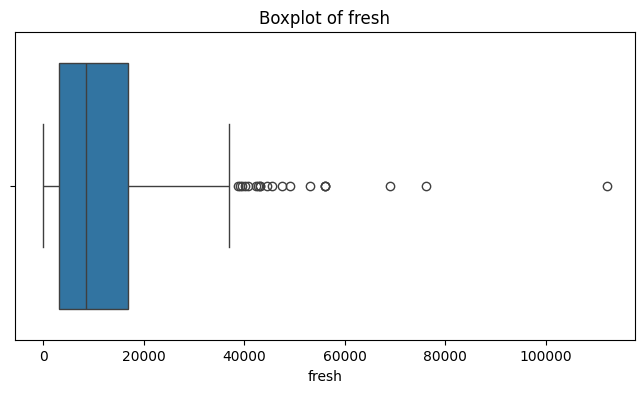

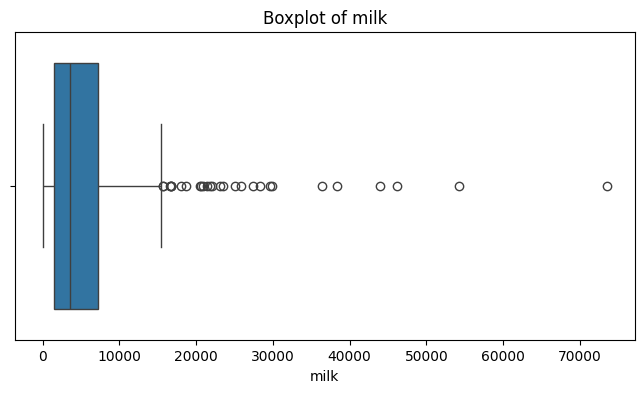

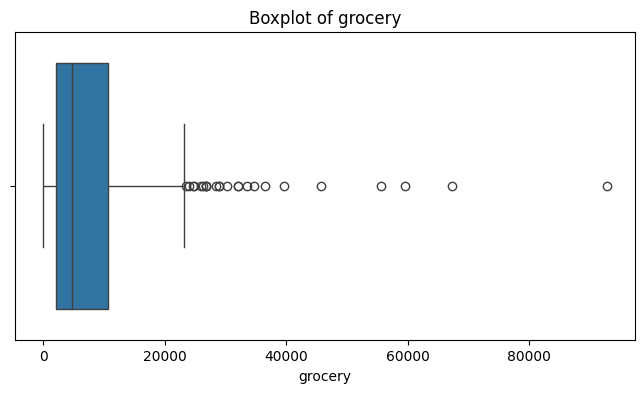

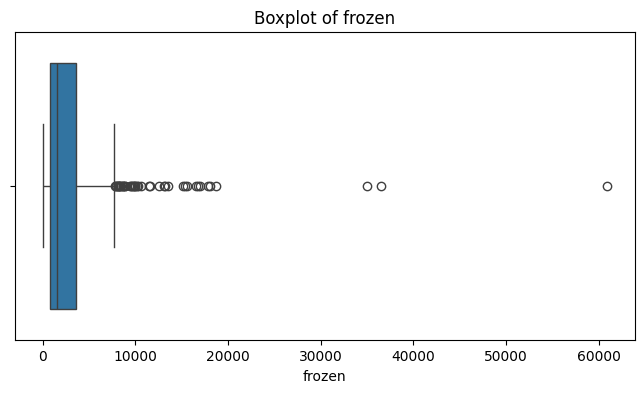

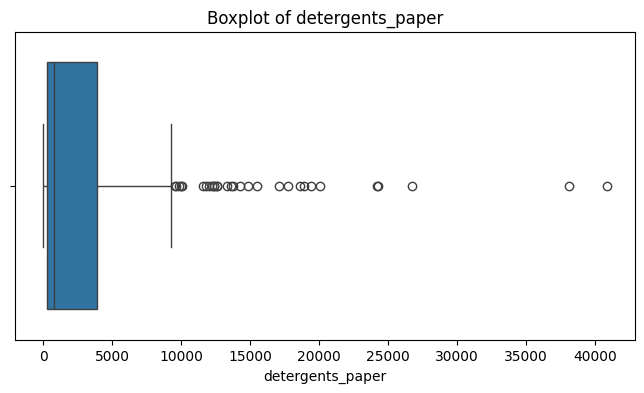

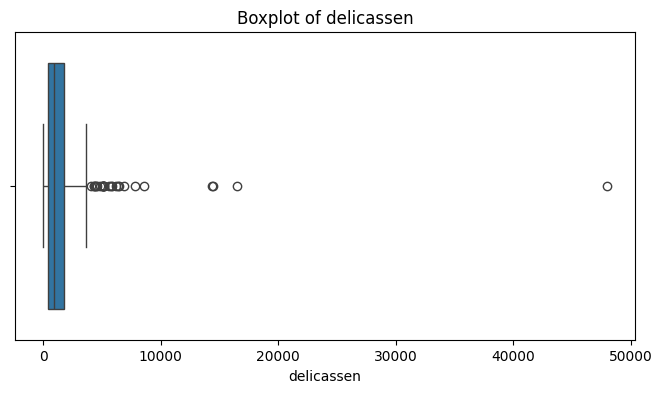

In [9]:
features = [
    "fresh", "milk", "grocery", "frozen",
    "detergents_paper", "delicassen"]
for col in features:

    plt.figure(figsize=(8,4))
    sns.boxplot(x=df_cust[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

# Exploratory Data Analysis (EDA)

## Statistics

In [10]:
df_cust.describe()

,fresh,milk,grocery,frozen,detergents_paper,delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [11]:
df_cust[features].var()

fresh               1.599549e+08
milk                5.446997e+07
grocery             9.031010e+07
frozen              2.356785e+07
detergents_paper    2.273244e+07
delicassen          7.952997e+06
dtype: float64

## Distributions

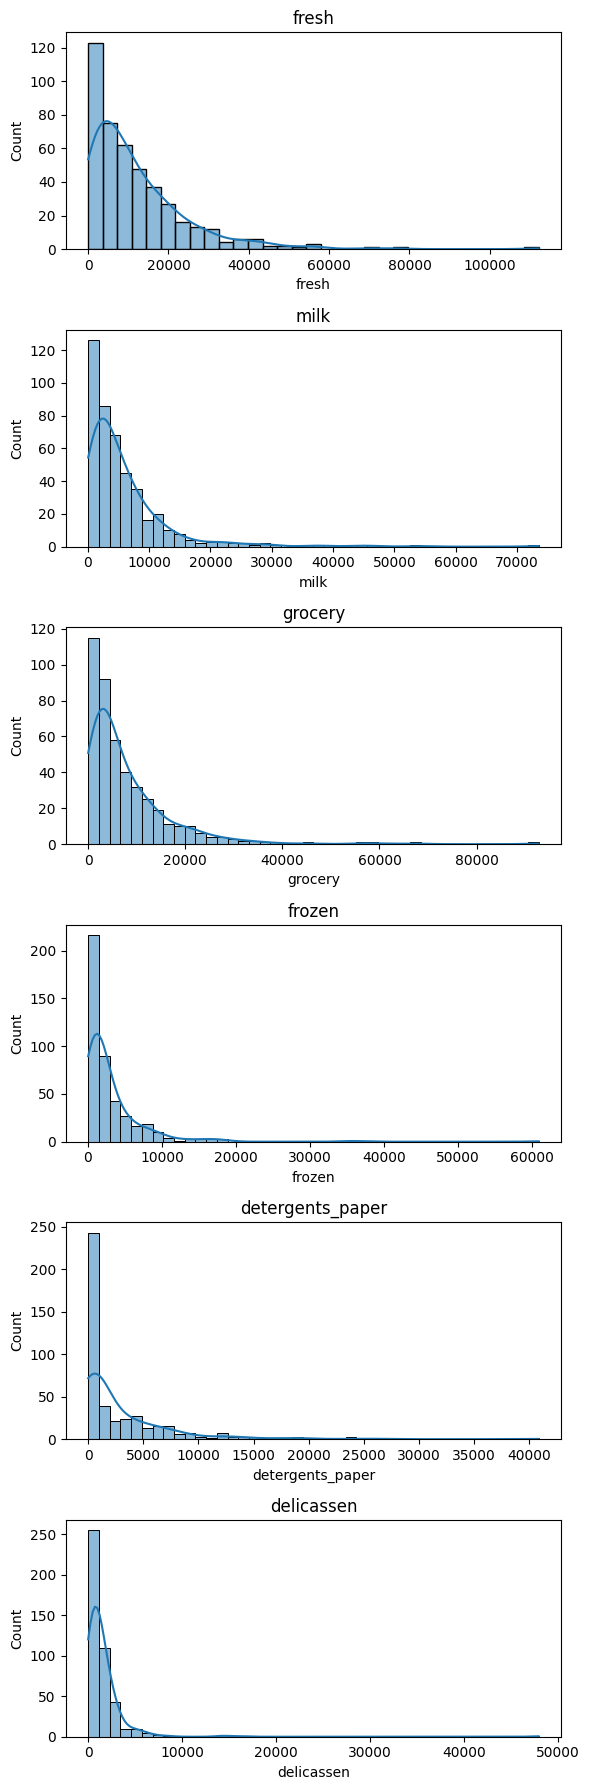

In [12]:
fig, axes = plt.subplots(nrows=len(features), #setting row number = feature number
                        ncols=1, 
                        figsize=(6, 3*len(features))) #dynamic figure size depending on feature size since they will be added below each other

#looping through each feature and plot its distribution
for i, col in enumerate(features):
    sns.histplot(data=df_cust, x=col, ax=axes[i], kde=True) #defining positioning and addition of line curves
    axes[i].set_title(col) #setting titles for each plot 

plt.tight_layout()
plt.show()

<Axes: xlabel='channel', ylabel='count'>

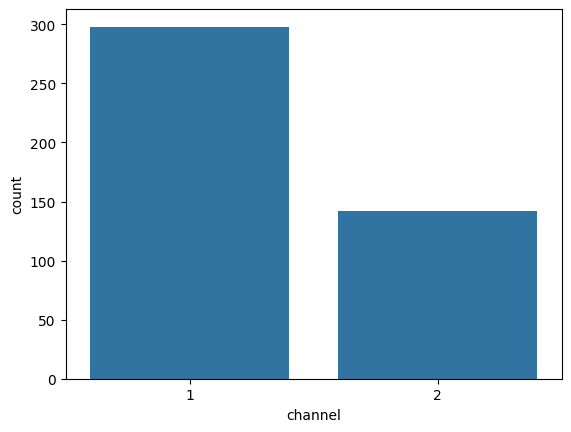

In [13]:
sns.countplot(x="channel", data=df_cust) #plotting distribution od binary variable across classes

<Axes: xlabel='region', ylabel='count'>

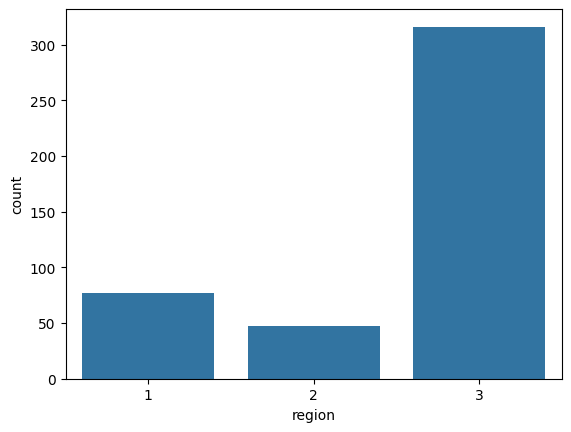

In [14]:
sns.countplot(x="region", data=df_cust)

## Correlations

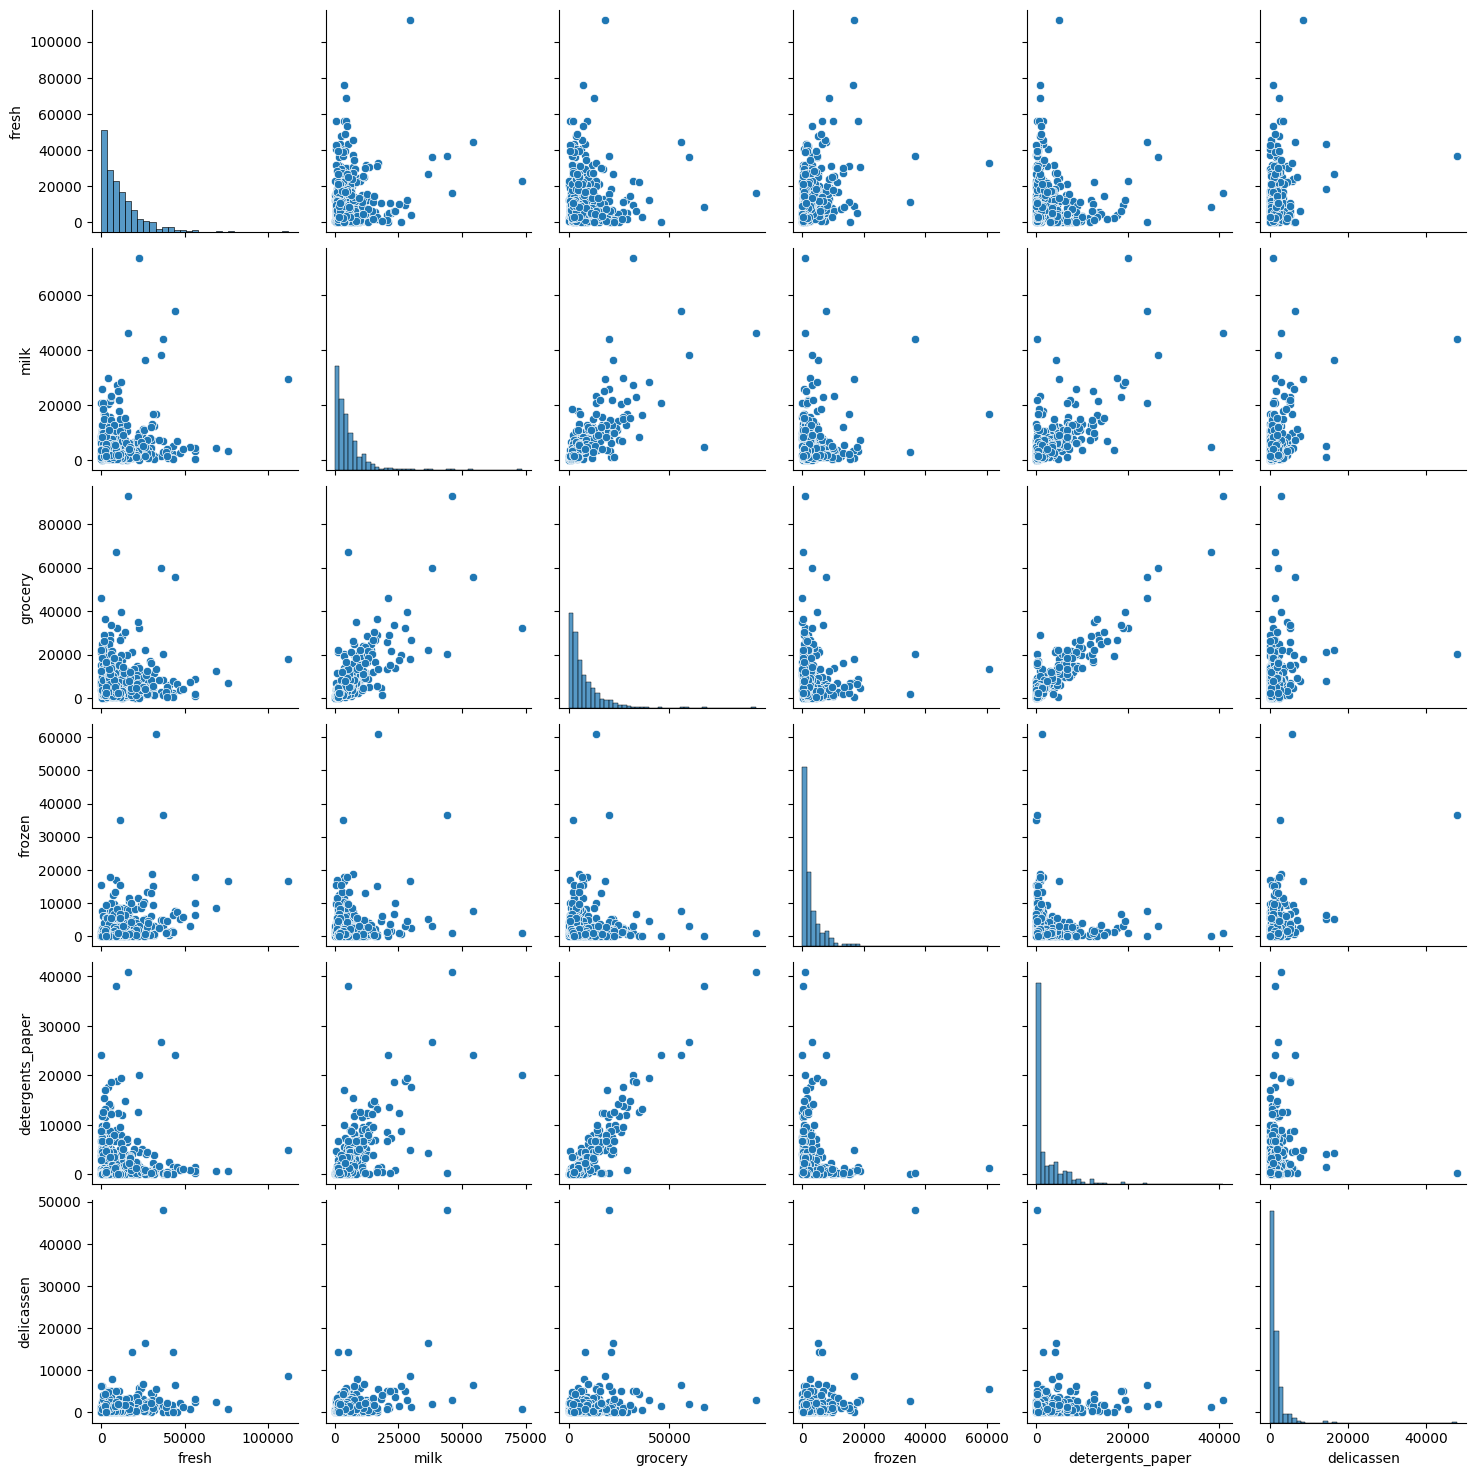

In [15]:
sns.pairplot(df_cust) 

In [16]:
correlations = df_cust[list(df_cust.columns)].drop(columns=['region','channel']).corr() #getting correlations dropping target no need
correlations

,fresh,milk,grocery,frozen,detergents_paper,delicassen
fresh,1.000000,0.100510,-0.011854,0.345881,-0.101953,0.244690
milk,0.100510,1.000000,0.728335,0.123994,0.661816,0.406368
grocery,-0.011854,0.728335,1.000000,-0.040193,0.924641,0.205497
frozen,0.345881,0.123994,-0.040193,1.000000,-0.131525,0.390947
detergents_paper,-0.101953,0.661816,0.924641,-0.131525,1.000000,0.069291
delicassen,0.244690,0.406368,0.205497,0.390947,0.069291,1.000000


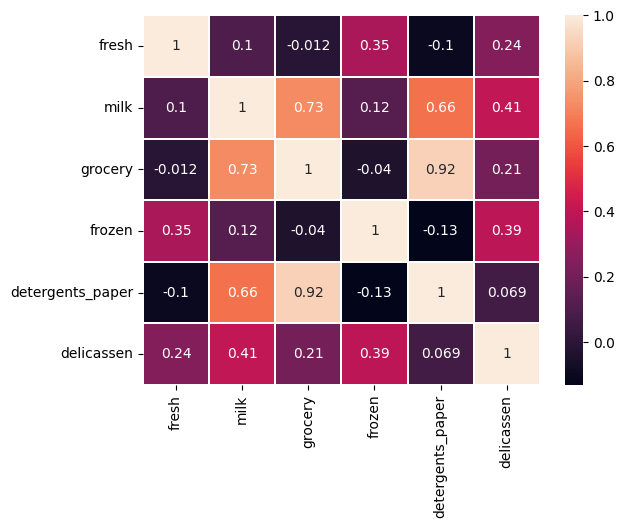

In [17]:
heat_map = sns.heatmap(
    correlations,
    annot=True, #disabling number displays
    linewidths=0.1
)

# Scaling


In [18]:
other_cols = ["region", "channel"]

In [19]:
df_features = df_cust[features] #columns to be scaled

In [20]:
# instantiating standard scaler
scaler =StandardScaler()
#scaling
features_scaled = scaler.fit_transform(df_features)

In [21]:
df_scaled = pd.DataFrame( # creating a dataframe with the scaled variables
    features_scaled,
    columns=features, 
    index=df_cust.index
) 

In [22]:
df_scaled= pd.concat( # merging new scaled variables and not scaled variables together 
    [df_cust[["region", "channel"]], df_scaled],
    axis=1
)

In [23]:
df_scaled.head()

,region,channel,fresh,milk,grocery,frozen,detergents_paper,delicassen
0,3,2,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,3,2,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,3,2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,3,1,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,3,2,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


# Principal Component Analysis

In [24]:
df_scaled.head()

,region,channel,fresh,milk,grocery,frozen,detergents_paper,delicassen
0,3,2,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,3,2,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,3,2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,3,1,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,3,2,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [25]:
X = df_scaled[features] # numeric variables are used in PCA

In [26]:
pca = PCA(n_components=6) # since we have 6 features, we check the explained variance ratio to decide how many to keep
pca.fit_transform(X)

array([[ 0.19329055, -0.30509996,  0.14087845, -0.48643154,  0.49528148,
        -0.00741414],
       [ 0.4344199 , -0.32841262, -0.31900662, -0.17883036,  0.36557931,
         0.05457185],
       [ 0.81114323,  0.8150957 , -1.52341562, -1.25408154, -0.37905353,
        -0.27753858],
       ...,
       [ 3.46570362, -1.03983801,  0.71316141,  0.0334078 , -0.53876786,
        -0.08534909],
       [-0.91802273, -0.03004659, -0.25840805, -0.52457824, -0.09321487,
        -0.028943  ],
       [-1.10513709, -0.86133787, -0.30515404, -0.11437678,  0.10990335,
         0.02897846]], shape=(440, 6))

In [27]:
pca.components_ 

array([[ 0.04288396,  0.54511832,  0.57925635,  0.05118859,  0.5486402 ,
         0.24868198],
       [ 0.52793212,  0.08316765, -0.14608818,  0.61127764, -0.25523316,
         0.50420705],
       [ 0.81225657, -0.06038798,  0.10838401, -0.17838615,  0.13619225,
        -0.52390412],
       [-0.23668559, -0.08718991,  0.10598745,  0.76868266,  0.17174406,
        -0.55206472],
       [-0.04868278,  0.82657929, -0.31499943, -0.02793224, -0.33964012,
        -0.31470051],
       [-0.03602539, -0.03804019,  0.72174458, -0.01563715, -0.68589373,
        -0.07513412]])

In [28]:
pca.explained_variance_ #variance explained by each component

array([2.65099857, 1.70646229, 0.74175057, 0.56501435, 0.28632709,
       0.06311455])

In [29]:
pca.explained_variance_ratio_ #cumulative variance explained by the components

array([0.44082893, 0.283764  , 0.12334413, 0.09395504, 0.04761272,
       0.01049519])

In [30]:
explained_variance_ratio_cumul_sum = np.cumsum(pca.explained_variance_ratio_)
explained_variance_ratio_cumul_sum 

array([0.44082893, 0.72459292, 0.84793705, 0.94189209, 0.98950481,
       1.        ])

## Determining the Number of Components

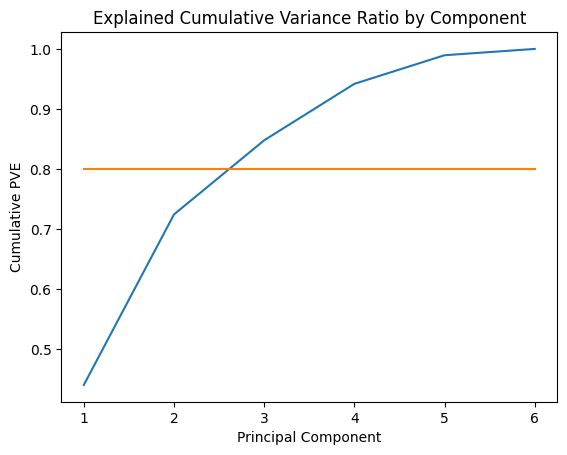

In [31]:
plt.title("Explained Cumulative Variance Ratio by Component")
plt.plot(np.arange(1, 7), explained_variance_ratio_cumul_sum)
plt.plot([1, 6], [0.8, 0.8])
plt.xlabel("Principal Component")
plt.ylabel("Cumulative PVE")
plt.show()

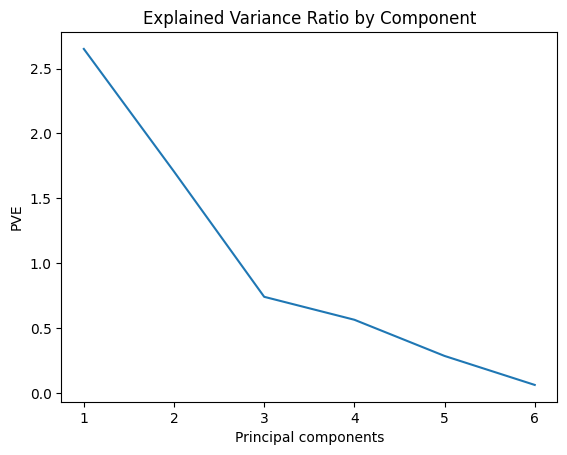

In [32]:
plt.title("Explained Variance Ratio by Component")
plt.plot(np.arange(1, 7), pca.explained_variance_)
plt.xlabel("Principal components")
plt.ylabel("PVE")
plt.show()

## Selected Principal Components

In [33]:
#reducing the dimensionality to 3 components based on the explained variance ratio plot and elbow method
pca = PCA(n_components=3)  
pca_components = pca.fit_transform(X)

In [34]:
#creating a DataFrame for the principal components with dates as index
pca_scores = pd.DataFrame(data=pca_components, index= X.index, columns=['PC1', 'PC2', 'PC3'])
pca_scores.head()

,PC1,PC2,PC3
0,0.193291,-0.305100,0.140878
1,0.434420,-0.328413,-0.319007
2,0.811143,0.815096,-1.523416
3,-0.778648,0.652754,-0.163012
4,0.166287,1.271434,-0.066279


In [35]:
#displaying the proportion of variance explained by each component
print("Explained Variance Ratio:")
for i, ratio in enumerate(pca.explained_variance_ratio_, start=1):
    print(f"PC{i}: {ratio:.2%}")

Explained Variance Ratio:
PC1: 44.08%
PC2: 28.38%
PC3: 12.33%


In [36]:
#showing the loadings (coefficients) for each variable
loadings = pca.components_.T  # Each column corresponds to a PC
# creating a DataFrame for the loadings with tickers as index
loadings_df = pd.DataFrame(data=loadings, index=X.columns, columns=['PC1', 'PC2', 'PC3'])
print(loadings_df)

                       PC1       PC2       PC3
fresh             0.042884  0.527932  0.812257
milk              0.545118  0.083168 -0.060388
grocery           0.579256 -0.146088  0.108384
frozen            0.051189  0.611278 -0.178386
detergents_paper  0.548640 -0.255233  0.136192
delicassen        0.248682  0.504207 -0.523904


correlationlari pc1 le azaltioyruz

In [37]:
df_pca = pd.concat([df_scaled, pca_scores], axis=1) # merging pca scores columns with the sclaed verison 

In [38]:
df_pca.head()

,region,channel,fresh,milk,grocery,frozen,detergents_paper,delicassen,PC1,PC2,PC3
0,3,2,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339,0.193291,-0.305100,0.140878
1,3,2,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151,0.434420,-0.328413,-0.319007
2,3,2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293,0.811143,0.815096,-1.523416
3,3,1,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411,-0.778648,0.652754,-0.163012
4,3,2,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347,0.166287,1.271434,-0.066279


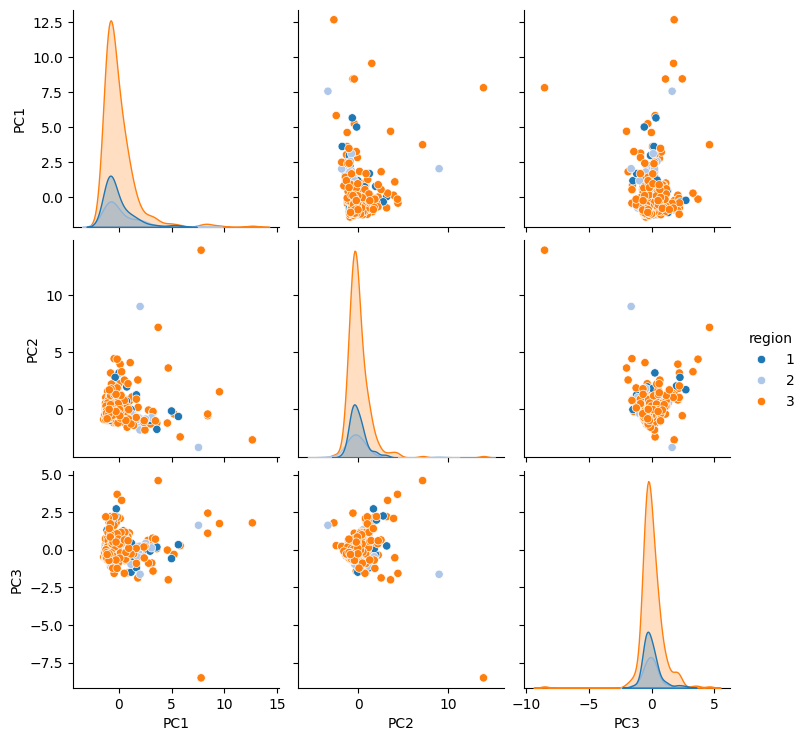

In [39]:
# plotting the first 3 principal components colored by region
sns.pairplot( 
    df_pca,
    vars=["PC1", "PC2",'PC3'],
    hue="region",
    palette="tab20"
)

/var/folders/j9/ffq41s8s6gn1vs5k2pdq30pr0000gn/T/ipykernel_13294/4230259771.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  region_pc_mean = df_pca.groupby("region")[pc_cols].mean()


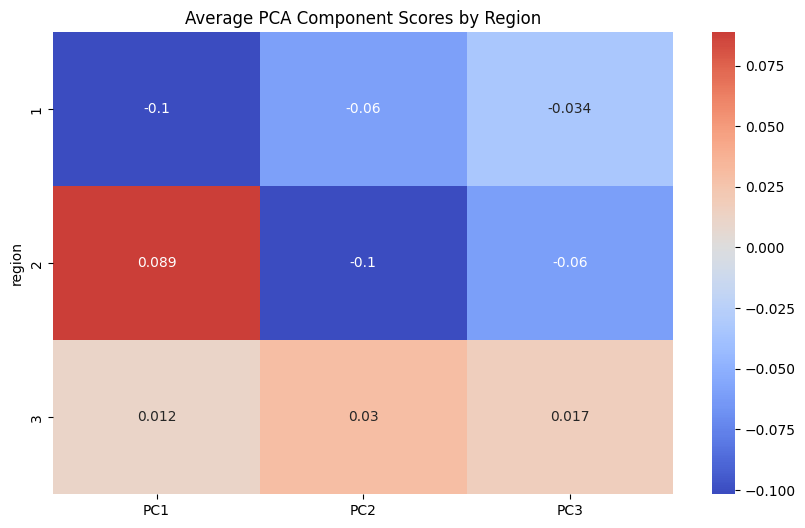

In [40]:
# creating pc columns just contains pca components
pc_cols = [c for c in df_pca.columns if c.startswith("PC")] 
region_pc_mean = df_pca.groupby("region")[pc_cols].mean()

# plotting the average PCA component scores by region using a heatmap
plt.figure(figsize=(10,6))

sns.heatmap(
    region_pc_mean,
    cmap="coolwarm",
    center=0,
    annot=True
)

plt.title("Average PCA Component Scores by Region")
plt.show()

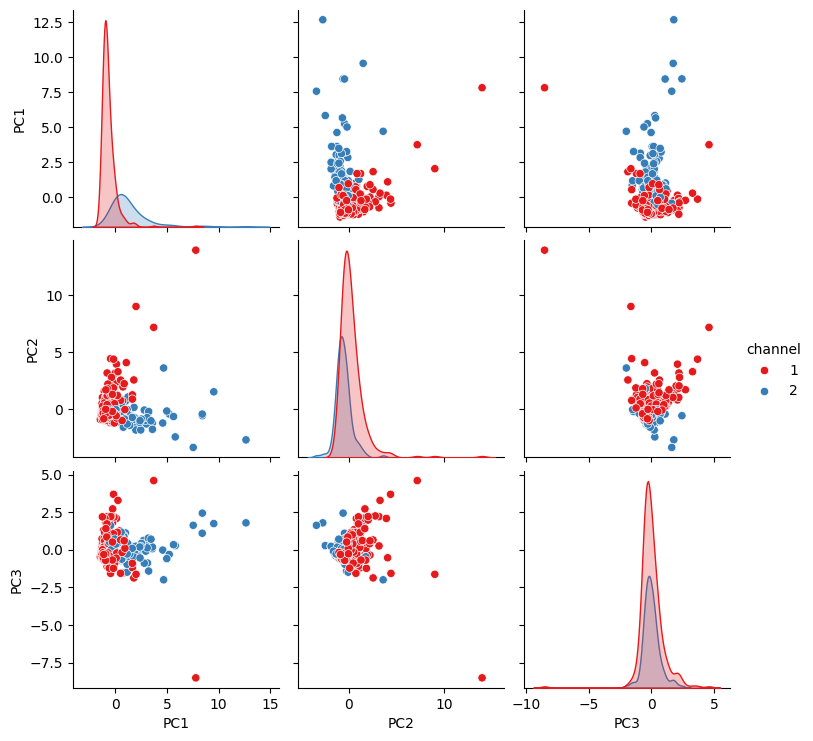

In [41]:
# plotting the first 3 principal components colored by channel
sns.pairplot(
    df_pca,
    vars=["PC1", "PC2", 'PC3'],
    hue="channel",
    palette = 'Set1'
)

/var/folders/j9/ffq41s8s6gn1vs5k2pdq30pr0000gn/T/ipykernel_13294/1713777475.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  channel_pc_mean = df_pca.groupby("channel")[pc_cols].mean()


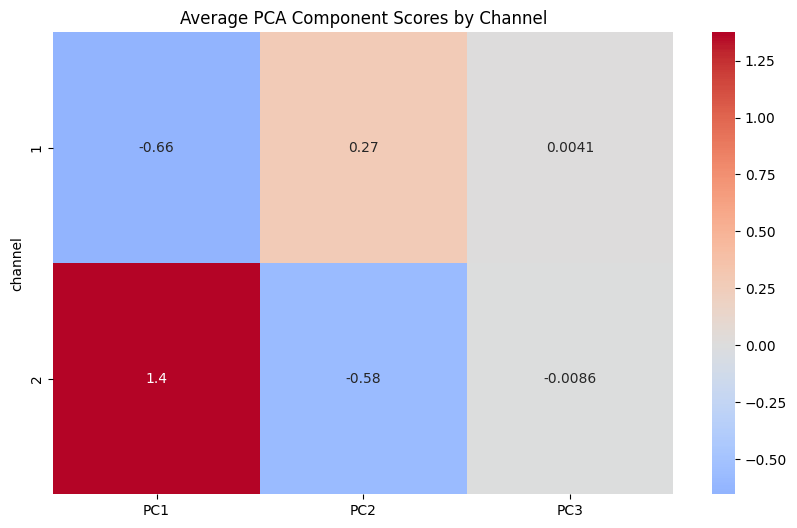

In [42]:
channel_pc_mean = df_pca.groupby("channel")[pc_cols].mean()

# plotting the average PCA component scores by channel using a heatmap

plt.figure(figsize=(10,6))

sns.heatmap(
    channel_pc_mean,
    cmap="coolwarm",
    center=0,
    annot=True
)

plt.title("Average PCA Component Scores by Channel")
plt.show()

In [43]:
# creating a 3D biplot with PCA scores and loadings

def biplot_3d(scores, coeff, labels=None):
    xs = scores[:, 0]
    ys = scores[:, 1]
    zs = scores[:, 2]

    # scaling  scores for better visualization
    scalex = 1.0 / (xs.max() - xs.min())
    scaley = 1.0 / (ys.max() - ys.min())
    scalez = 1.0 / (zs.max() - zs.min())

    fig = plt.figure(figsize=(18, 14))
    ax = fig.add_subplot(111, projection='3d')

    # plotting  the PCA scores
    ax.scatter(xs * scalex, ys * scaley, zs * scalez, c='grey', alpha=0.5)

    # ploting arrows for variable loadings
    for i in range(coeff.shape[0]):
        ax.quiver(
            0, 0, 0,
            coeff[i, 0], coeff[i, 1], coeff[i, 2],
            color='r',
            arrow_length_ratio=0.05
        )
        # labelling the arrows with variable names
        if labels is None:
            ax.text(
                coeff[i, 0] * 1.1,
                coeff[i, 1] * 1.1,
                coeff[i, 2] * 1.1,
                f"Var{i+1}",
                color='g',
                fontsize=10
            )
        else:
            ax.text(
                coeff[i, 0] * 1.1,
                coeff[i, 1] * 1.1,
                coeff[i, 2] * 1.1,
                labels[i],
                color='b',
                fontsize=10
            )


    ax.set_xlabel("PC1",labelpad=15)
    ax.set_ylabel("PC2",labelpad=15)
    ax.set_zlabel("PC3",labelpad=20)
    
    ax.view_init(elev=25, azim=40)

    plt.tight_layout()
    plt.show()

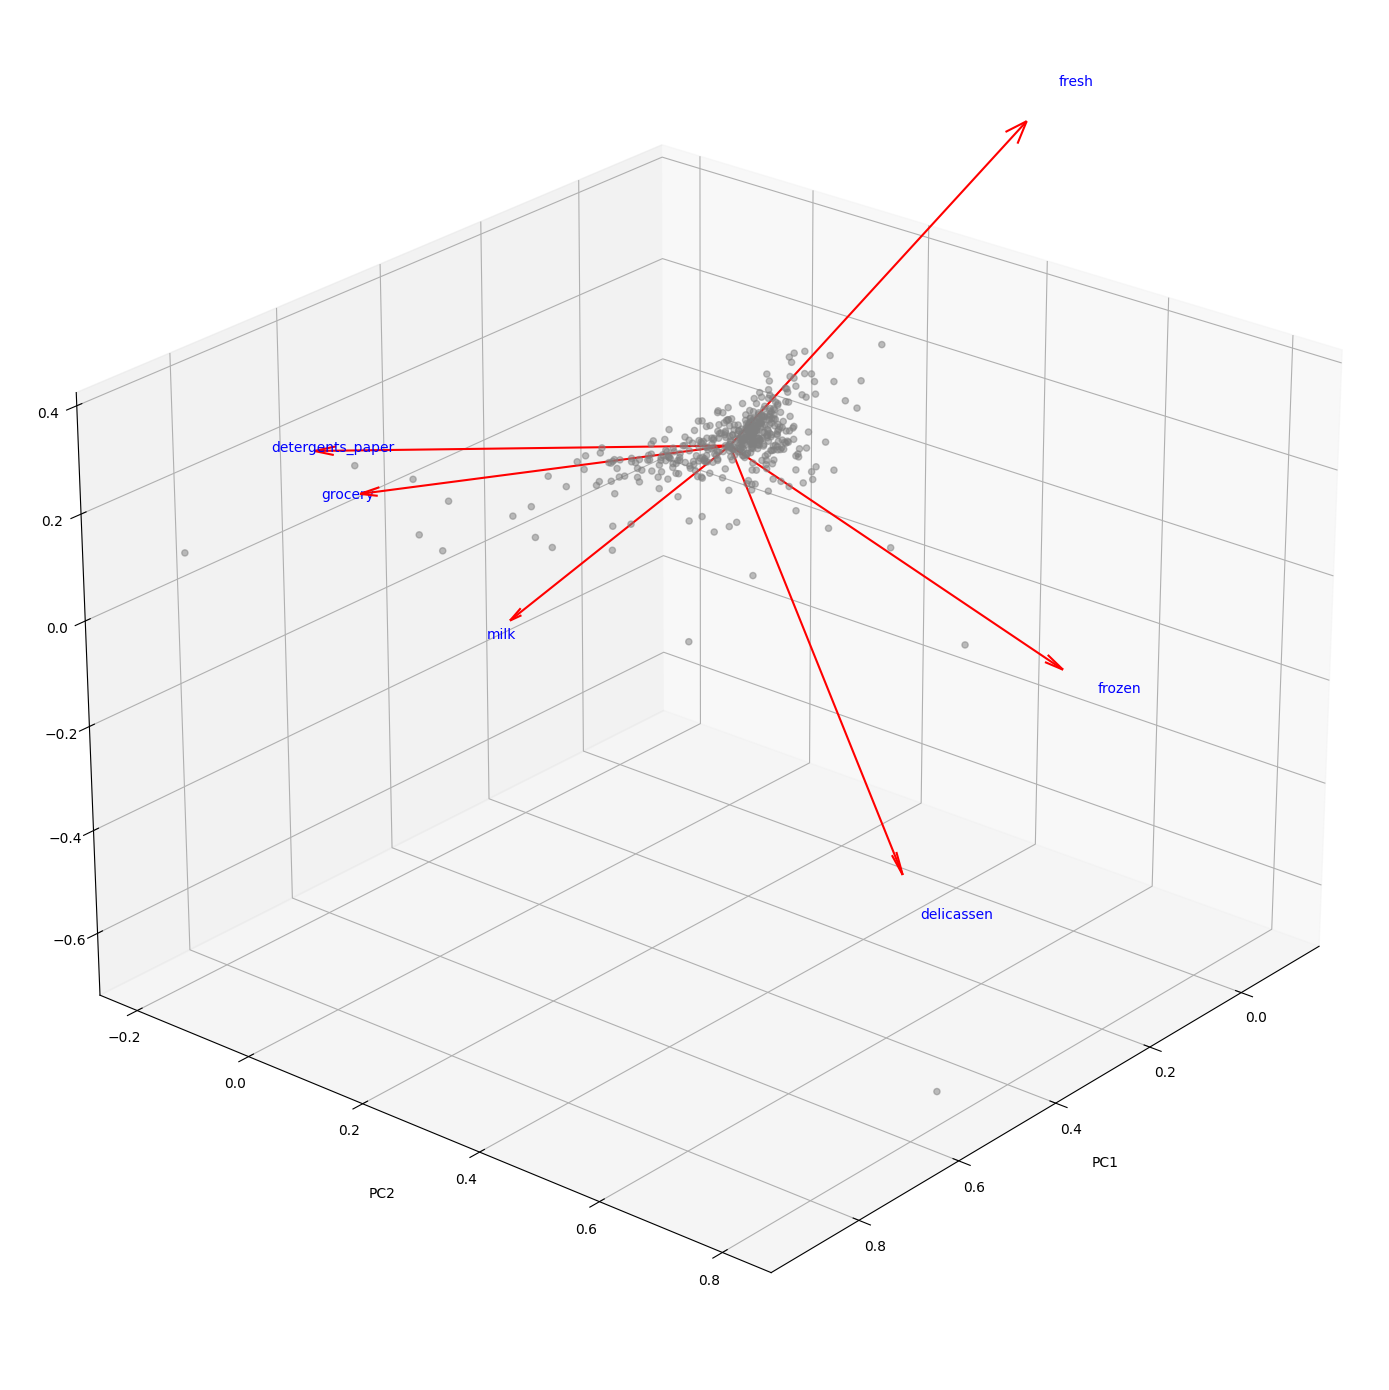

In [44]:
#creating a 3D biplot with PCA scores and loadings
biplot_3d(pca_components, pca.components_.T, labels=X.columns)

# Clustering

## K-means Clustering

## Determining the Optimal Number of Clusters

In [45]:
df_pca.head()

,region,channel,fresh,milk,grocery,frozen,detergents_paper,delicassen,PC1,PC2,PC3
0,3,2,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339,0.193291,-0.305100,0.140878
1,3,2,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151,0.434420,-0.328413,-0.319007
2,3,2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293,0.811143,0.815096,-1.523416
3,3,1,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411,-0.778648,0.652754,-0.163012
4,3,2,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347,0.166287,1.271434,-0.066279


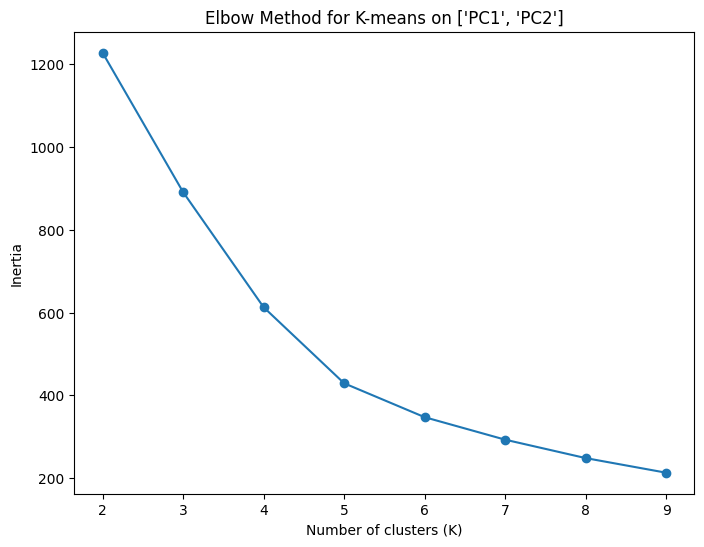

In [46]:
K = range(2, 10) #defining the number of clusters to test
columns=["PC1", "PC2"]

X_kmeans = df_pca[columns]
inertia_K = [] # prepaing a list to store results
    
for k in K: # running K-means for each K
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X_kmeans)
    inertia_K.append(kmeanModel.inertia_)
    
plt.figure(figsize=(8, 6))
plt.plot(K, inertia_K, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title(f"Elbow Method for K-means on {columns}")
plt.show()

In [47]:
#running K-means for a few selected K values to evaluate silhouette scores
for k in [2, 3, 4, 5]: 
    kmeans = KMeans(n_clusters=k, random_state=111, n_init=10)
    labels = kmeans.fit_predict(X_kmeans)

    sample_sil = silhouette_samples(X_kmeans, labels) # silhouette score for each sample

    sil_df = pd.DataFrame({
        "cluster": labels,
        "silhouette": sample_sil 
    })

    cluster_scores = sil_df.groupby("cluster")["silhouette"].mean()

    print(f"\nK = {k}")
    print(f"cluster_{k}")
    print("Overall silhouette score:", silhouette_score(X_kmeans, labels))
    print("Per-cluster silhouette scores:")
    print(cluster_scores)


K = 2
cluster_2
Overall silhouette score: 0.6362204119808383
Per-cluster silhouette scores:
cluster
0    0.684856
1    0.209306
Name: silhouette, dtype: float64

K = 3
cluster_3
Overall silhouette score: 0.4827737202150244
Per-cluster silhouette scores:
cluster
0    0.518219
1    0.014024
2    0.425961
Name: silhouette, dtype: float64

K = 4
cluster_4
Overall silhouette score: 0.48521964473348217
Per-cluster silhouette scores:
cluster
0    0.512196
1    0.301104
2    0.419988
3    0.433976
Name: silhouette, dtype: float64

K = 5
cluster_5
Overall silhouette score: 0.48582979569929063
Per-cluster silhouette scores:
cluster
0    0.558885
1    0.290866
2    0.411740
3    0.352483
4    0.332034
Name: silhouette, dtype: float64


In [48]:
# checking the cluster size for each K
for k in [2, 3, 4, 5]: 
    kmeans = KMeans(n_clusters=k, random_state=111, n_init=10)
    labels = kmeans.fit_predict(X_kmeans)

    df_pca[f"cluster_{k}"] = labels
    
    print(f"\nK = {k}")
    print(df_pca[f"cluster_{k}"].value_counts().sort_index())


K = 2
cluster_2
0    395
1     45
Name: count, dtype: int64

K = 3
cluster_3
0    329
1     13
2     98
Name: count, dtype: int64

K = 4
cluster_4
0    325
1     11
2    101
3      3
Name: count, dtype: int64

K = 5
cluster_5
0    267
1     11
2     94
3      3
4     65
Name: count, dtype: int64


## K-means Clustering Results with n=2

In [49]:
# running K-means on the PCA component data
kmeans = KMeans(n_clusters=2, random_state=111, n_init=10).fit(X_kmeans)

In [50]:
# extracting the cluster labels
labels = kmeans.labels_

# adding the labels back into the dataframe
df_pca["cluster"] = labels

# checking  cluster sizes
value_counts = df_pca["cluster"].value_counts().sort_index()
print("Cluster sizes:")
print(value_counts)

Cluster sizes:
cluster
0    395
1     45
Name: count, dtype: int64


In [51]:
cluster_centers = pd.DataFrame(kmeans.cluster_centers_, columns=pc_cols[:2])
cluster_centers.round(3)

,PC1,PC2
0,-0.419,0.046
1,3.674,-0.408


In [52]:
df_pca.head()

,region,channel,fresh,milk,grocery,frozen,detergents_paper,delicassen,PC1,PC2,PC3,cluster_2,cluster_3,cluster_4,cluster_5,cluster
0,3,2,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339,0.193291,-0.305100,0.140878,0,0,0,0,0
1,3,2,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151,0.434420,-0.328413,-0.319007,0,2,2,2,0
2,3,2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293,0.811143,0.815096,-1.523416,0,0,2,4,0
3,3,1,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411,-0.778648,0.652754,-0.163012,0,0,0,0,0
4,3,2,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347,0.166287,1.271434,-0.066279,0,0,0,4,0


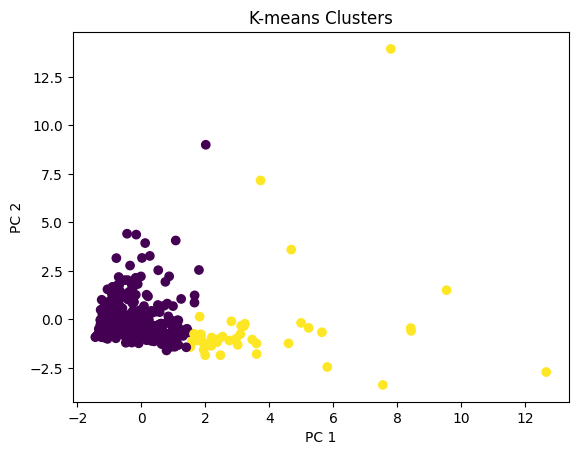

In [ ]:
#plotting the k-means clusters in the PCA space
plt.scatter(df_pca["PC1"], df_pca["PC2"], c=labels)
plt.title("K-means Clusters")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.show()

In [54]:
# looking at the PCA component scores for each cluster
df_pca.groupby('cluster')[['PC1','PC2','PC3']].mean()

,PC1,PC2,PC3
cluster,,,
0,-0.418589,0.046426,-0.001684
1,3.674284,-0.407514,0.014783


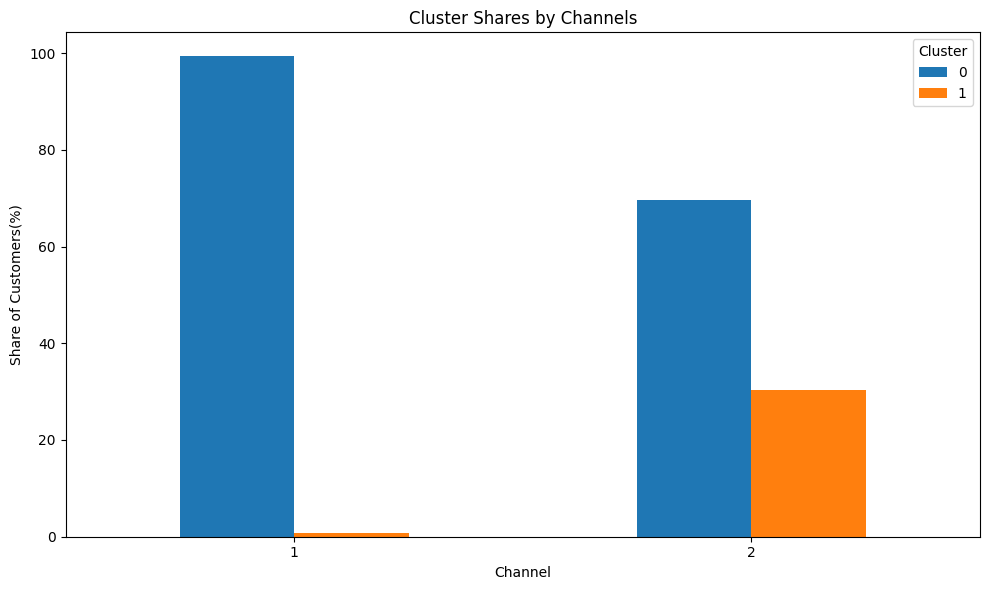

In [ ]:
# the distribution of the clusters by channels
channel_cluster_share = (
    pd.crosstab(df_pca["channel"], df_pca["cluster"], normalize="index") * 100 # calculating the percentage of each cluster within each channel
)

# plotting the cluster shares by channel
ax = channel_cluster_share.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Channel")
plt.ylabel("Share of Customers(%)")
plt.title("Cluster Shares by Channels")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

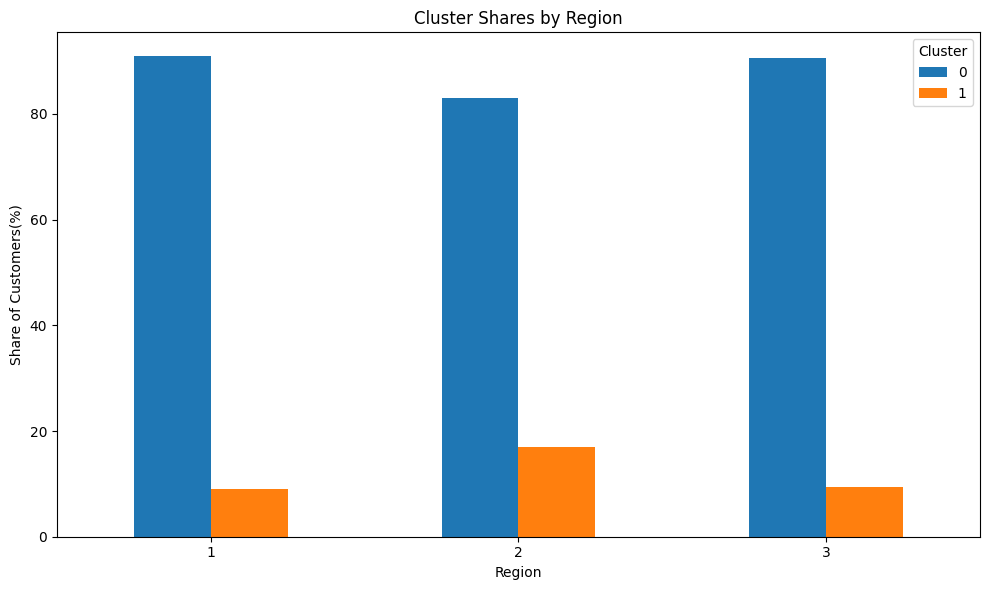

In [ ]:
# the distribution of the clusters by region 
region_cluster_share = (
    pd.crosstab(df_pca["region"], df_pca["cluster"], normalize="index") * 100 # calculating the percentage of each cluster within each region
)

# plotting the cluster shares by region
ax = region_cluster_share.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Region")
plt.ylabel("Share of Customers(%)")
plt.title("Cluster Shares by Region")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

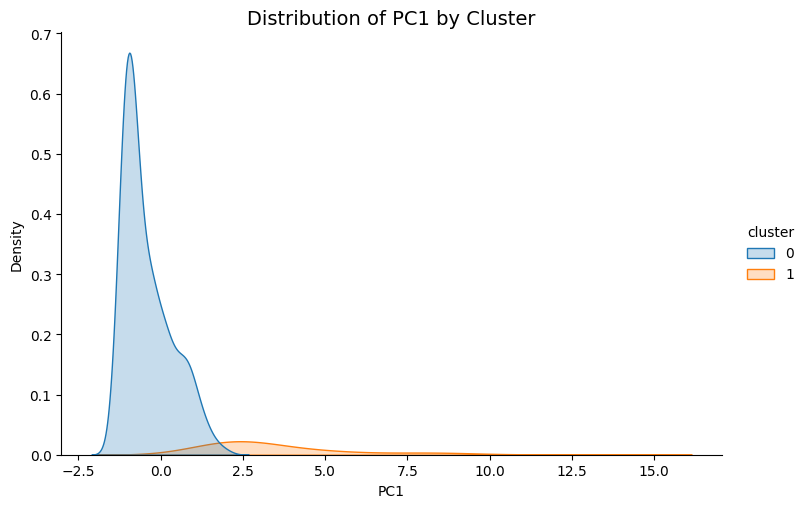

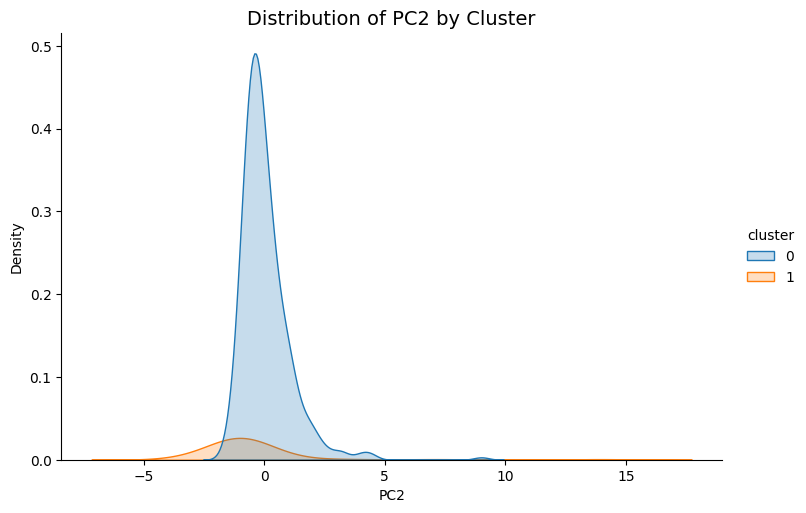

In [ ]:
# plotting the distribution of the PCA components by cluster
for col in ['PC1', 'PC2']:
    sns.displot(df_pca, x=col, hue="cluster",
                kind="kde", fill=True, height=5, aspect=1.5, palette="tab10")
    plt.title(f"Distribution of {col} by Cluster", fontsize=14)
    plt.show()

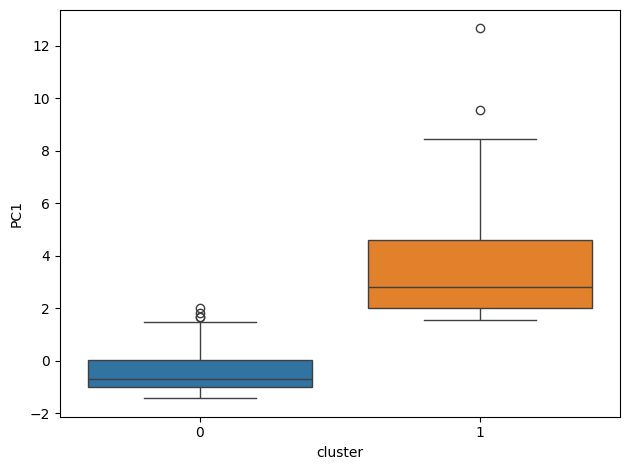

In [ ]:
# plotting boxplot of the PC1 component by cluster
sns.boxplot(
    x=df_pca["cluster"],
    y=df_pca["PC1"],
    hue=df_pca["cluster"],
    palette="tab10",
    legend=False
)
plt.tight_layout()

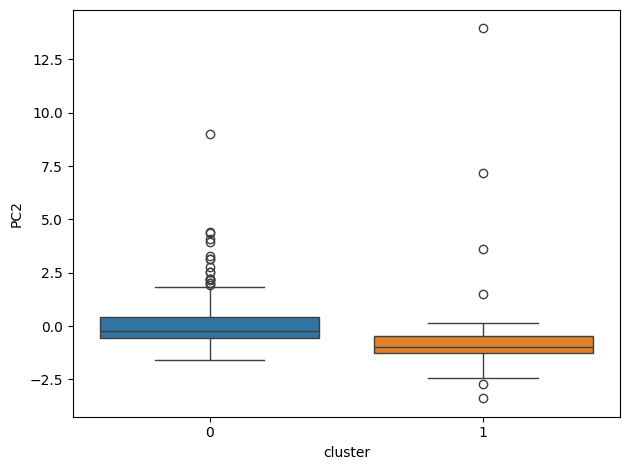

In [ ]:
# plotting boxplot of the PC2 component by cluster
sns.boxplot(
    x=df_pca["cluster"],
    y=df_pca["PC2"],
    hue=df_pca["cluster"],
    palette="tab10",
    legend=False
)
plt.tight_layout()

# Hierarcical Clustering

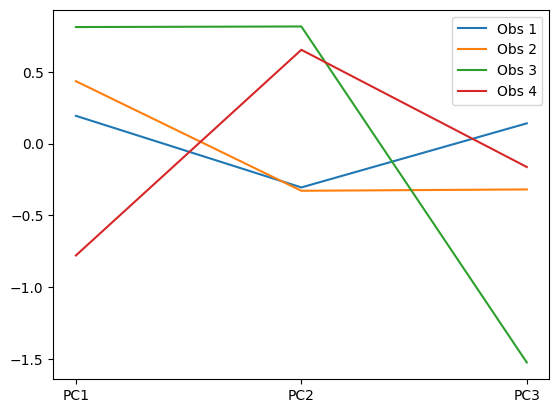

In [60]:
# plotting the PCA scores for the first few observations to see how they are positioned in the PCA space
plt.plot(pca_scores.iloc[0], label='Obs 1')
plt.plot(pca_scores.iloc[1], label='Obs 2')
plt.plot(pca_scores.iloc[2], label='Obs 3')
plt.plot(pca_scores.iloc[3], label='Obs 4')
plt.legend()
plt.show()

In [ ]:
columns= ["PC1", "PC2"] # selecting two PCA components to use for hierarchical clustering
X_hier = df_pca[columns].copy()


HClust = AgglomerativeClustering 

#instantiating hierarchical clustering model with ward linkage and euclidean distance
hc_ward = HClust(
    distance_threshold=0,
    n_clusters=None,
    linkage='ward',
    metric='euclidean'
)

hc_ward.fit(X_hier)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",None
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",0
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [ ]:
#instantiating hierarchical clustering model with complete linkage and euclidean distance
hc_comp = HClust(
    distance_threshold=0,
    n_clusters=None,
    linkage='complete',
    metric='euclidean'
)

hc_comp.fit(X_hier)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",None
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'complete'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",0
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


## Choosing the best Linkage

### Ward Linkage

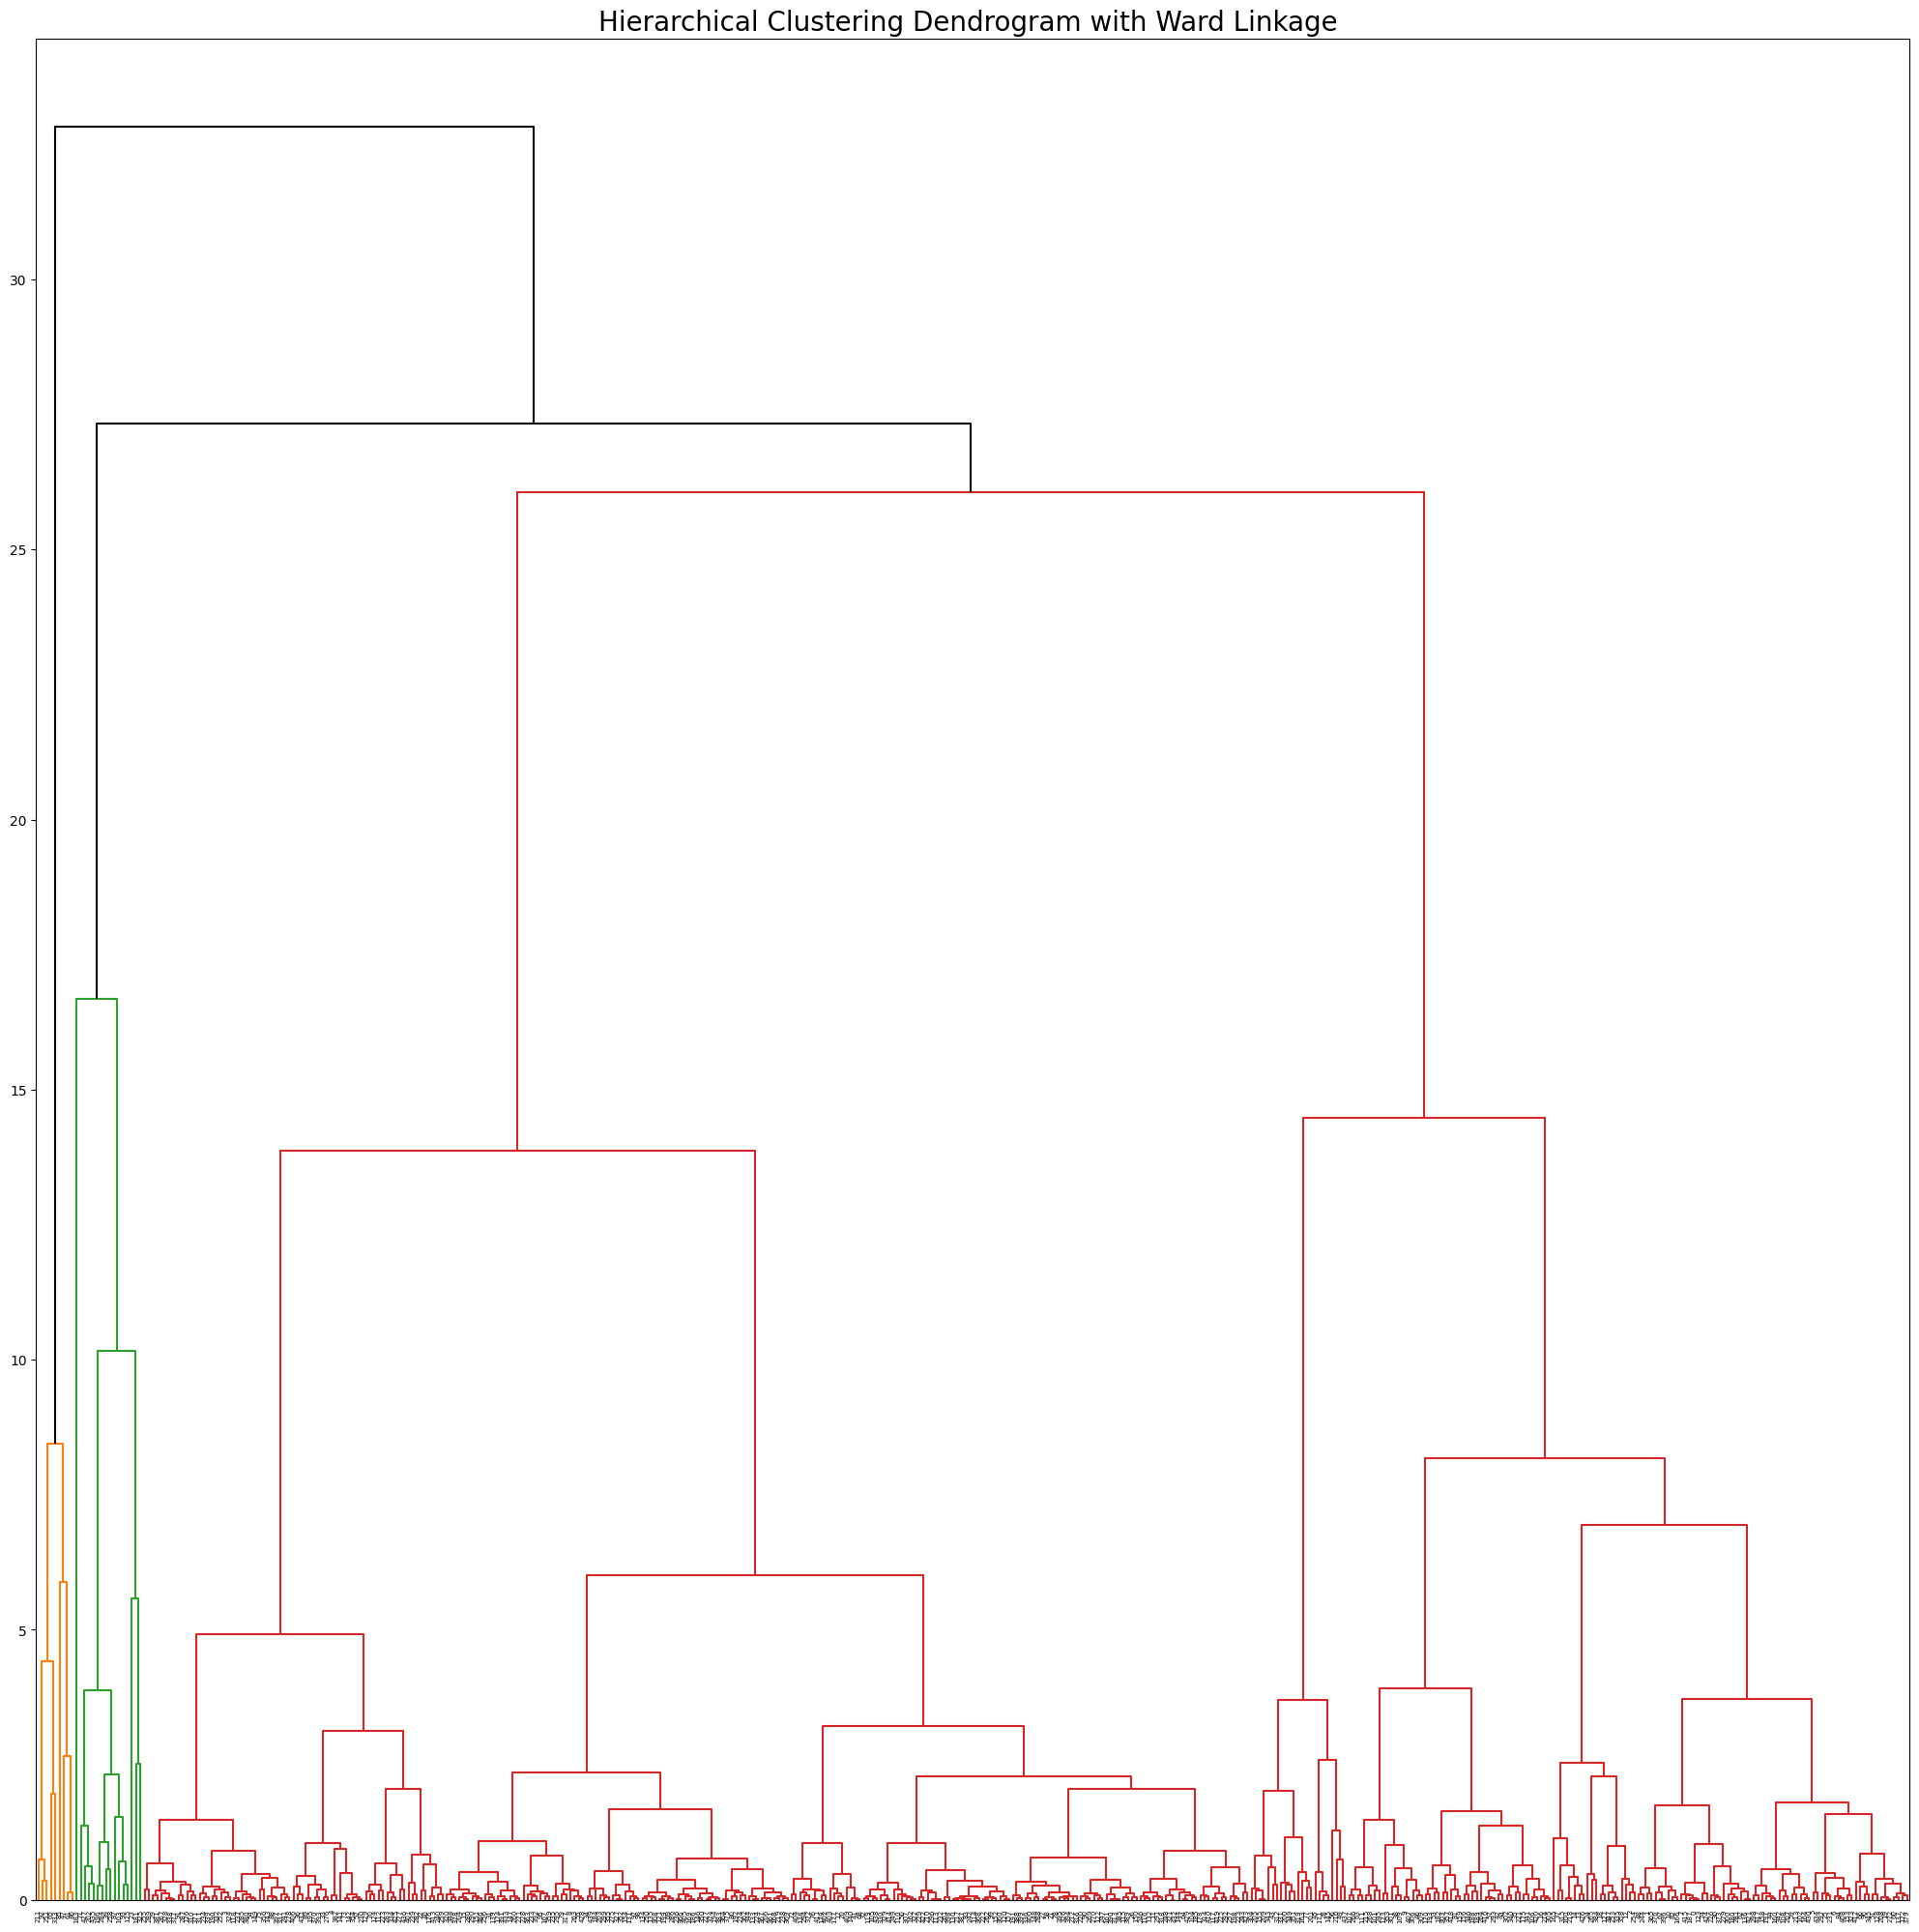

In [ ]:
# plotting the dendrogram for ward linkage
cargs = {'color_threshold':-np.inf,
         'above_threshold_color':'black'}
linkage_ward = compute_linkage(hc_ward)
fig, ax = plt.subplots(1, 1, figsize=(25, 25))
dendrogram(linkage_ward, 
           ax=ax,
           color_threshold=27, # cutting at 27
           above_threshold_color='black')

ax.set_title("Hierarchical Clustering Dendrogram with Ward Linkage ", fontsize=20)

plt.show()

In [ ]:
ward_cut = cut_tree(linkage_ward, height = 27).T # cutting it at 27 

In [ ]:
labels_ward = ward_cut.flatten() # flattening the array to get cluster labels for each observation

In [ ]:
X_hier.loc[:, "ward_cluster"] = labels_ward # adding the cluster labels to the hierarchical clustering dataframe

In [67]:
X_hier['ward_cluster'].value_counts() #checking cluster sizes for ward linkage

ward_cluster
0    415
1     16
2      9
Name: count, dtype: int64

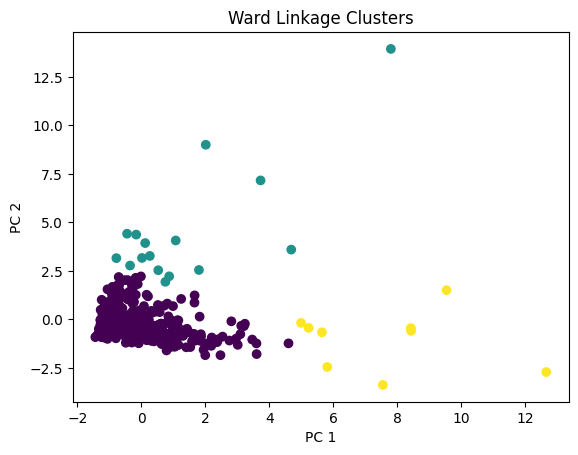

In [68]:
#plotting the clusters in the PCA space for ward linkage
plt.scatter(X_hier.iloc[:, 0], X_hier.iloc[:, 1], c=labels_ward) 
plt.title("Ward Linkage Clusters")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.show()

In [69]:
print(silhouette_score(X_hier, labels_ward)) #silhouette score for ward linkage

0.6827623394753173


In [70]:
df_final = pd.concat([df_pca, X_hier[["ward_cluster"]]], axis=1) # merging pca scores columns with the sclaed verison 

In [71]:
df_final.groupby('ward_cluster')[['PC1','PC2','PC3']].mean() # checking the PCA component scores for each cluster for ward linkage

,PC1,PC2,PC3
ward_cluster,,,
0,-0.217339,-0.151268,-0.028389
1,1.370508,4.508639,0.205888
2,7.585296,-1.040239,0.943008


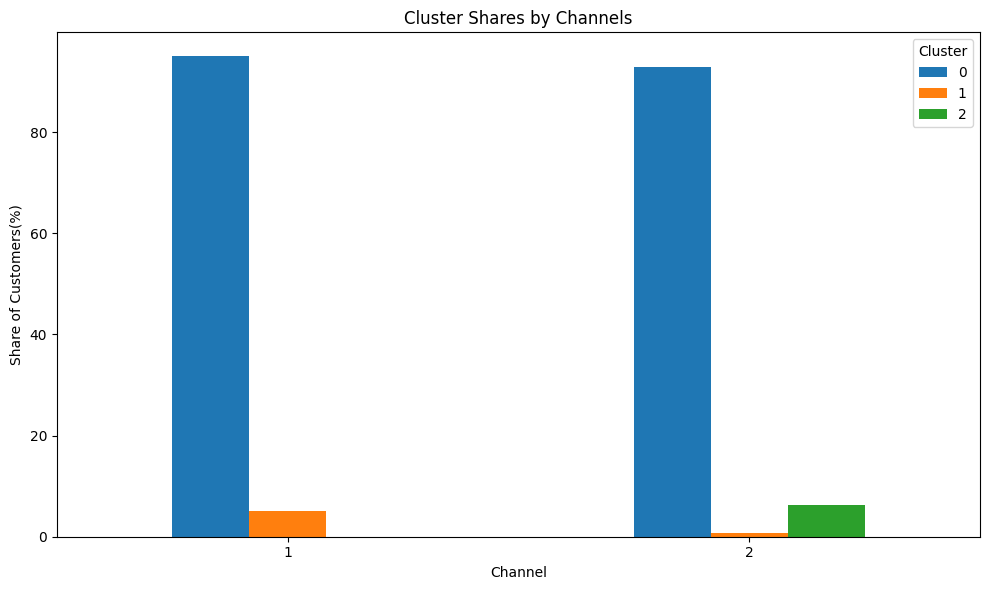

In [ ]:
# the distribution of the clusters by channels for ward linkage
channel_cluster_share = (
    pd.crosstab(df_final["channel"], df_final["ward_cluster"], normalize="index") * 100
)
# plotting the cluster shares by channel for ward linkage
ax = channel_cluster_share.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Channel")
plt.ylabel("Share of Customers(%)")
plt.title("Cluster Shares by Channels")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

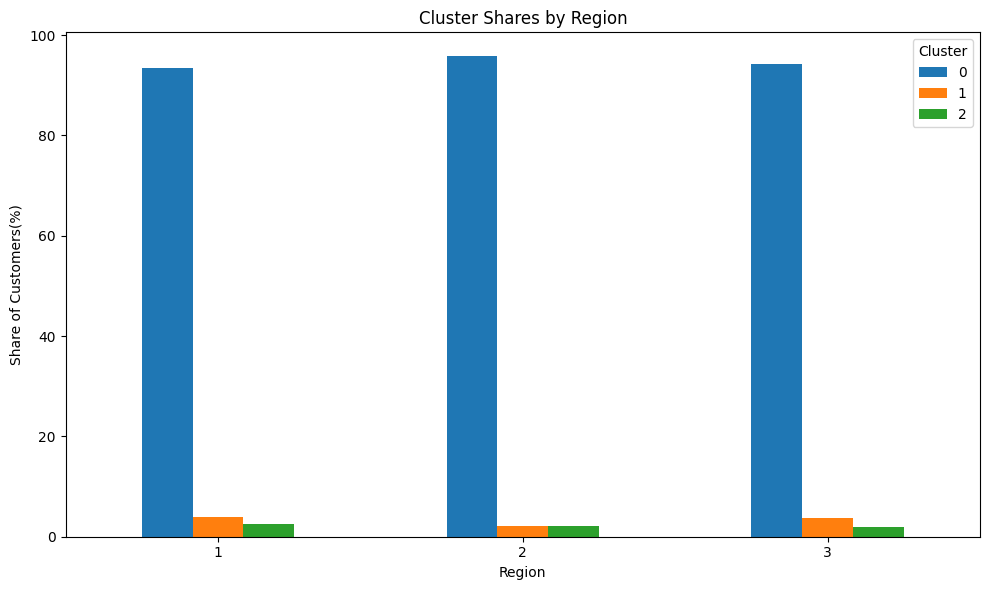

In [73]:
# plotting the cluster shares by region for ward linkage
region_cluster_share = (
    pd.crosstab(df_final["region"], df_final["ward_cluster"], normalize="index") * 100
)

ax = region_cluster_share.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Region")
plt.ylabel("Share of Customers(%)")
plt.title("Cluster Shares by Region")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

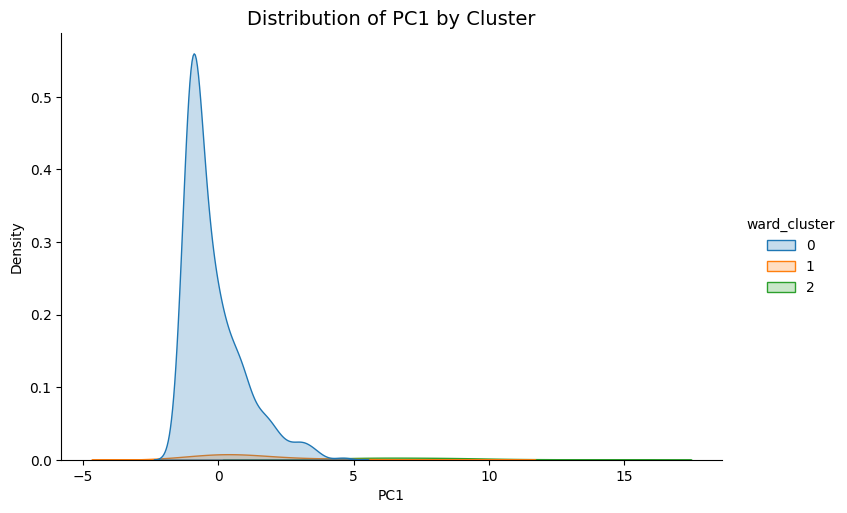

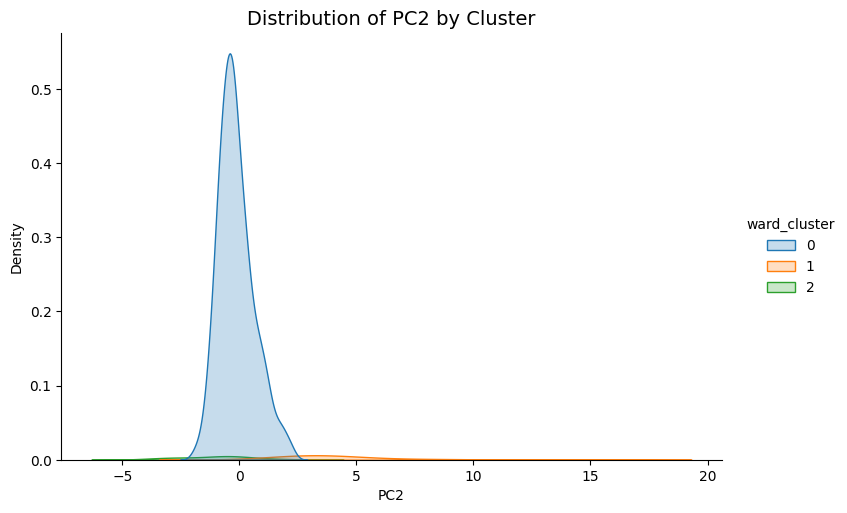

In [ ]:
#plotting the distribution of PC components by cluster for ward linkage
for col in ['PC1','PC2']:
    sns.displot(df_final, x=col, hue="ward_cluster",
                kind="kde", fill=True, height=5, aspect=1.5, palette="tab10")
    plt.title(f"Distribution of {col} by Cluster", fontsize=14)
    plt.show()

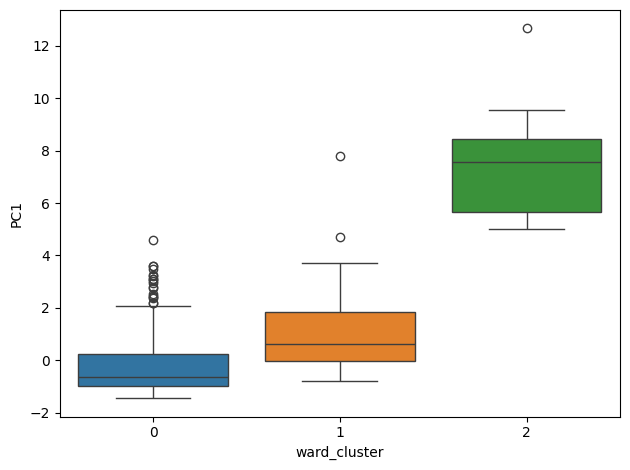

In [ ]:
sns.boxplot( #plotting boxplots of PC1 component by cluster for ward linkage
    x=df_final["ward_cluster"],
    y=df_final["PC1"],
    hue=df_final["ward_cluster"],
    palette="tab10",
    legend=False
)
plt.tight_layout()


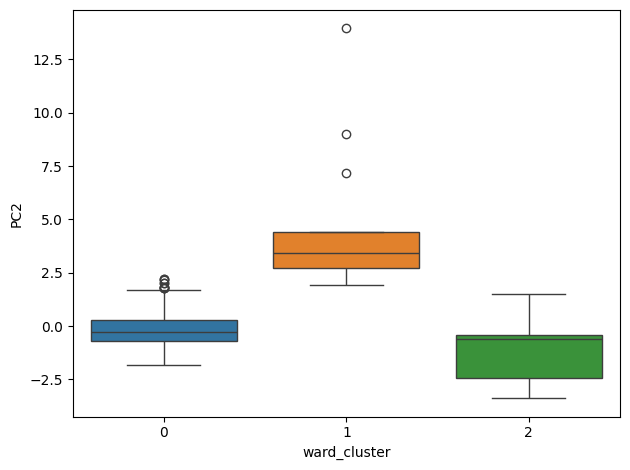

In [ ]:
sns.boxplot( #plotting boxplots of PC2 component by cluster for ward linkage
    x=df_final["ward_cluster"],
    y=df_final["PC2"],
    hue=df_final["ward_cluster"],
    palette="tab10",
    legend=False
)
plt.tight_layout()

### Complete Linkage

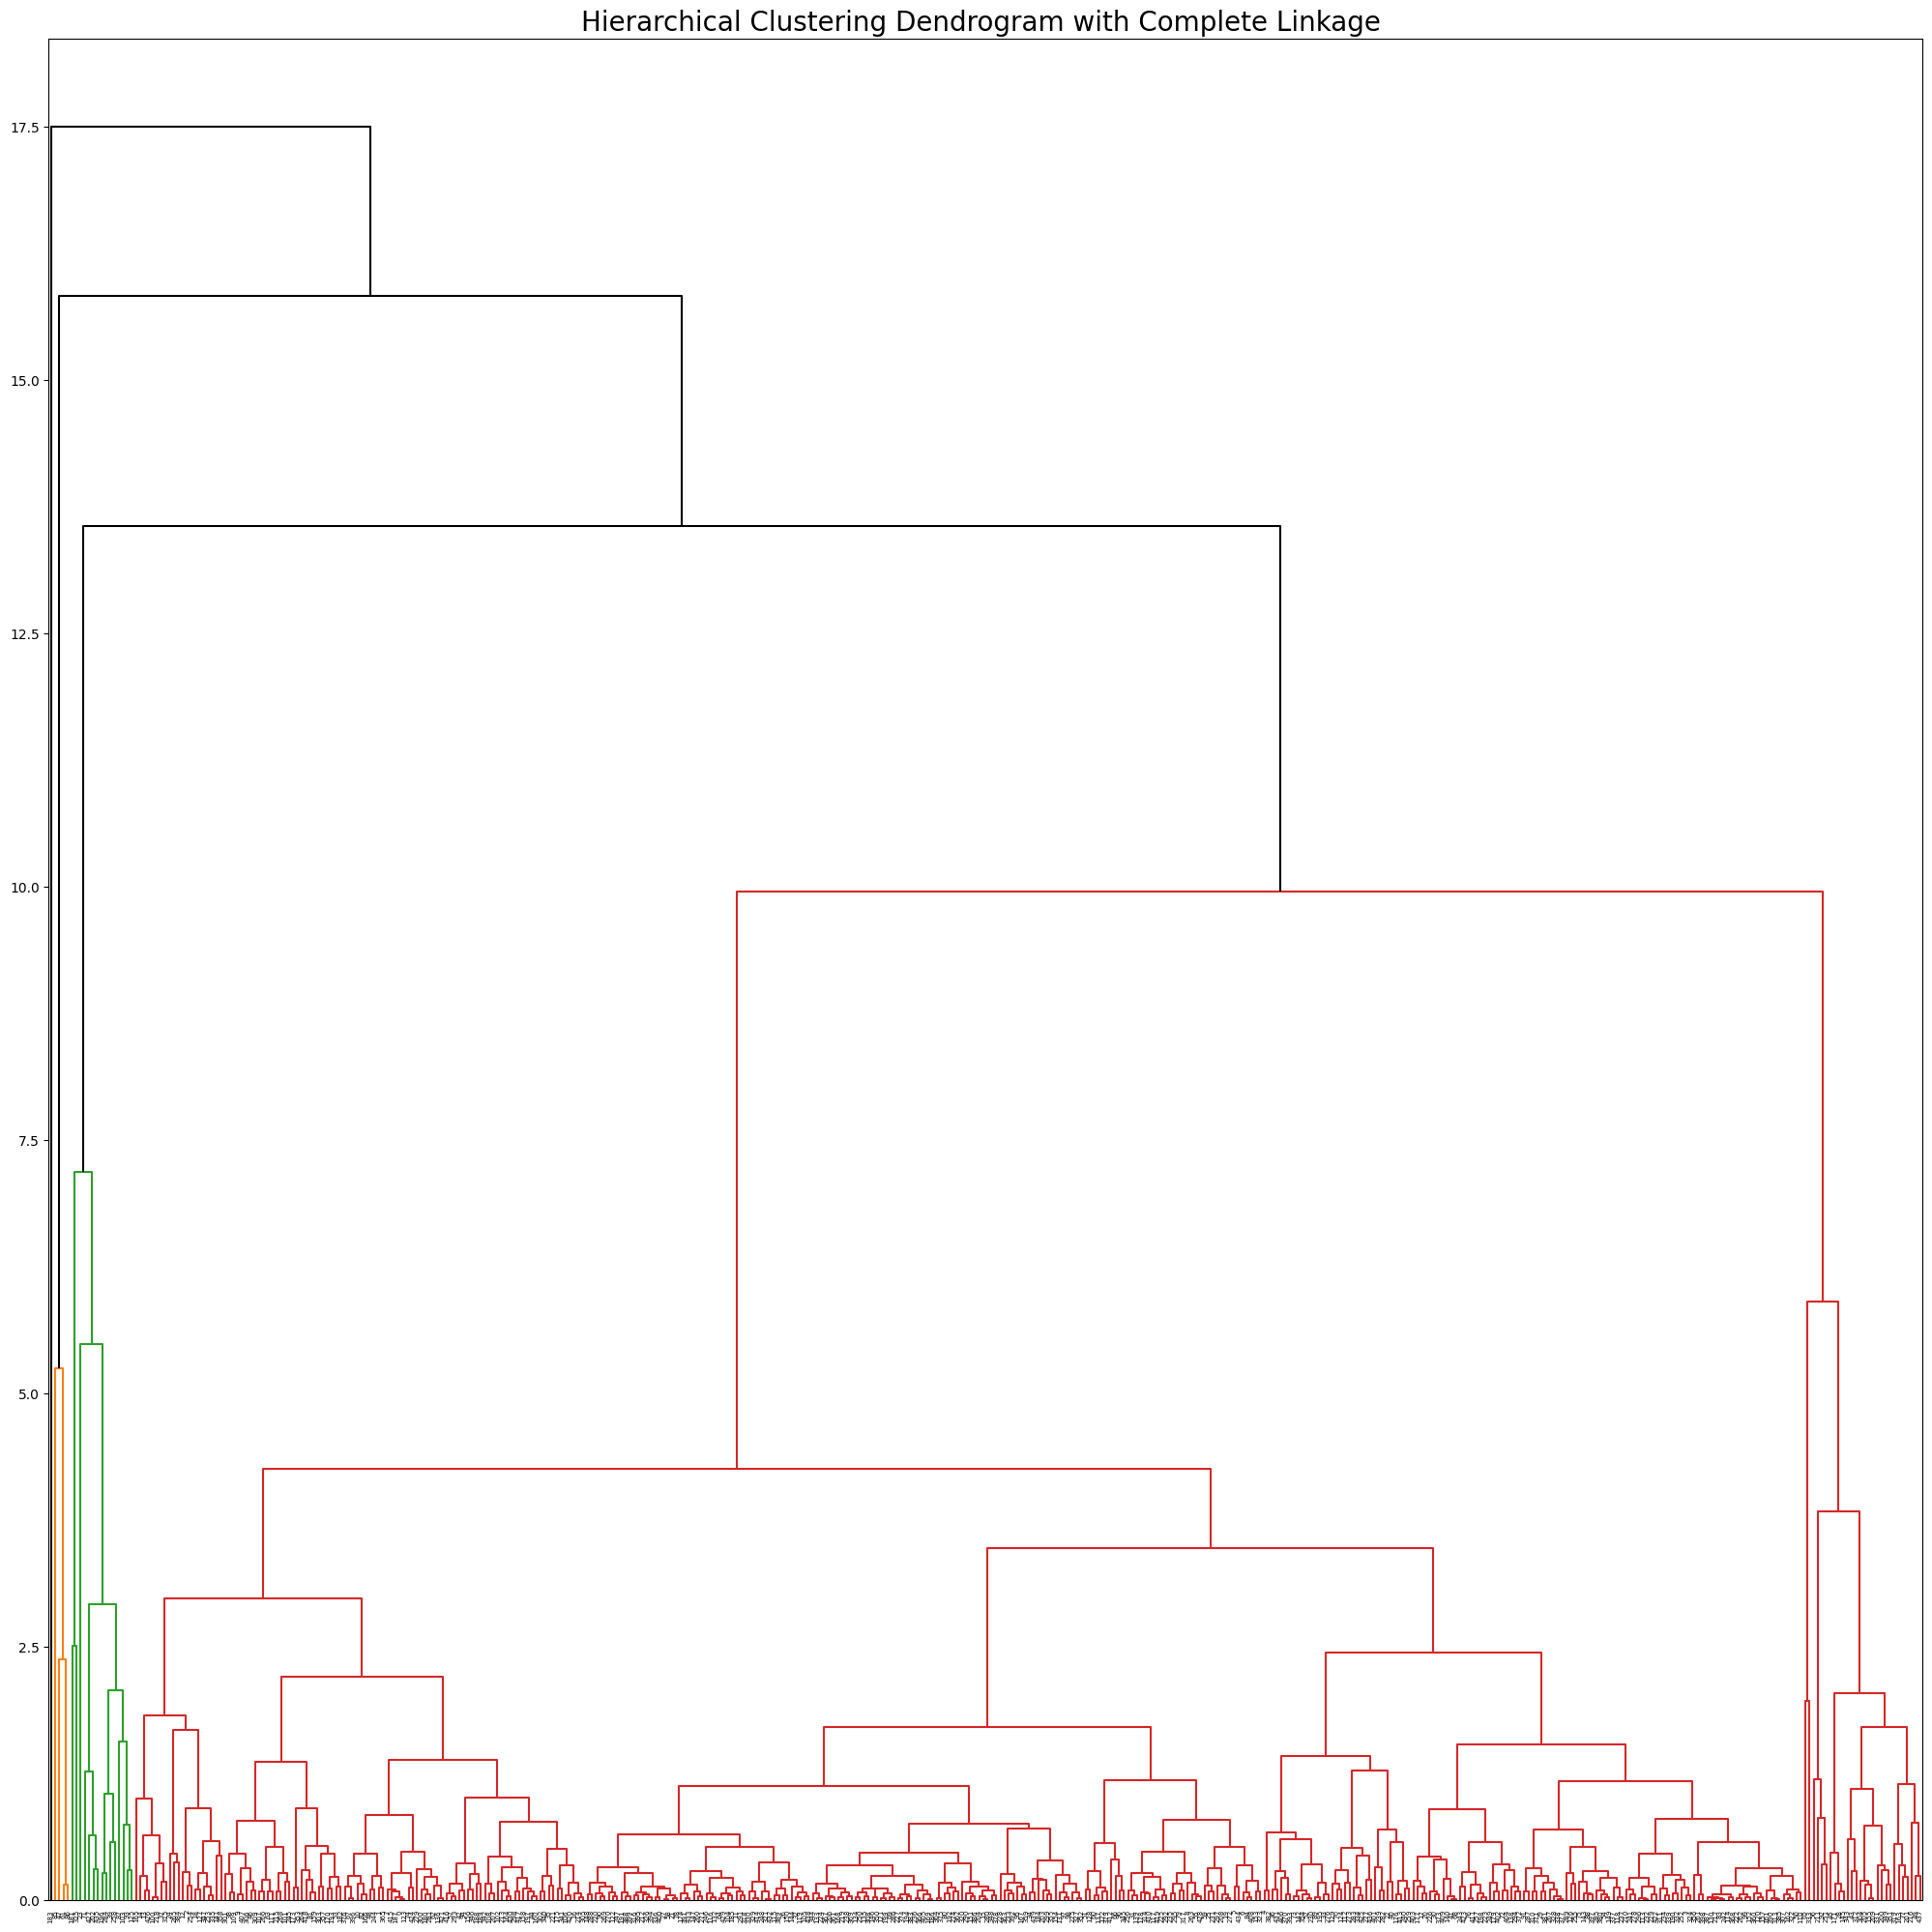

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(25, 25))
linkage_comp = compute_linkage(hc_comp)
dendrogram(linkage_comp, #plotting the dendrogram for complete linkage
           ax=ax,
           color_threshold=12.5, # cutting at 12.5
           above_threshold_color='black')

ax.set_title("Hierarchical Clustering Dendrogram with Complete Linkage ", fontsize=20)

plt.show()

In [ ]:
comp_cut = cut_tree(linkage_comp, height = 12.5).T # cutting the complete linkage dendrogram at 12.5

In [ ]:
labels = comp_cut.flatten() #flattening the array to get cluster labels for each observation

In [ ]:
X_hier.loc[:, "comp_cluster"] = labels # adding the complete linkage cluster labels to the hierarchical clustering dataframe

In [ ]:
X_hier['comp_cluster'].value_counts() #checking cluster sizes for complete linkage

comp_cluster
0    420
1     15
2      4
3      1
Name: count, dtype: int64

In [82]:
print(silhouette_score(X_hier, labels)) # silhouette score for complete linkage

0.6381837562255808


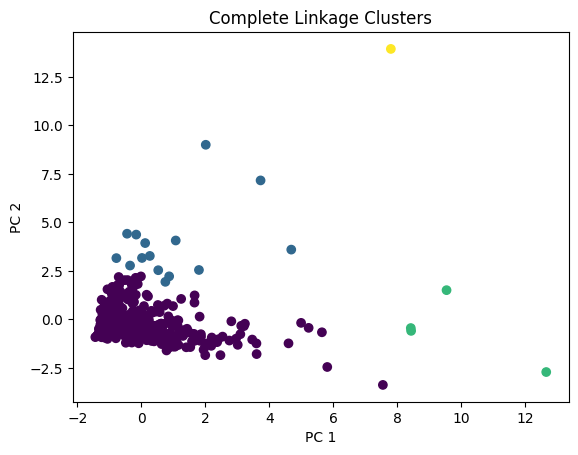

In [ ]:
plt.scatter(X_hier.iloc[:, 0], X_hier.iloc[:, 1], c=labels) # plotting the clusters in the PCA space
plt.title("Complete Linkage Clusters")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.show()

In [84]:
df_pca.head()

,region,channel,fresh,milk,grocery,frozen,detergents_paper,delicassen,PC1,PC2,PC3,cluster_2,cluster_3,cluster_4,cluster_5,cluster
0,3,2,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339,0.193291,-0.305100,0.140878,0,0,0,0,0
1,3,2,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151,0.434420,-0.328413,-0.319007,0,2,2,2,0
2,3,2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293,0.811143,0.815096,-1.523416,0,0,2,4,0
3,3,1,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411,-0.778648,0.652754,-0.163012,0,0,0,0,0
4,3,2,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347,0.166287,1.271434,-0.066279,0,0,0,4,0


In [85]:
df_final = pd.concat([df_pca, X_hier[["comp_cluster"]]], axis=1) # merging pca scores columns with the sclaed verison 

In [86]:
df_final.groupby('comp_cluster')[['PC1','PC2','PC3']].mean() # checking the PCA component scores for each cluster

,PC1,PC2,PC3
comp_cluster,,,
0,-0.145169,-0.166408,-0.024754
1,0.942012,3.879276,0.787289
2,9.760758,-0.561699,1.775636
3,7.797940,13.949084,-8.515130


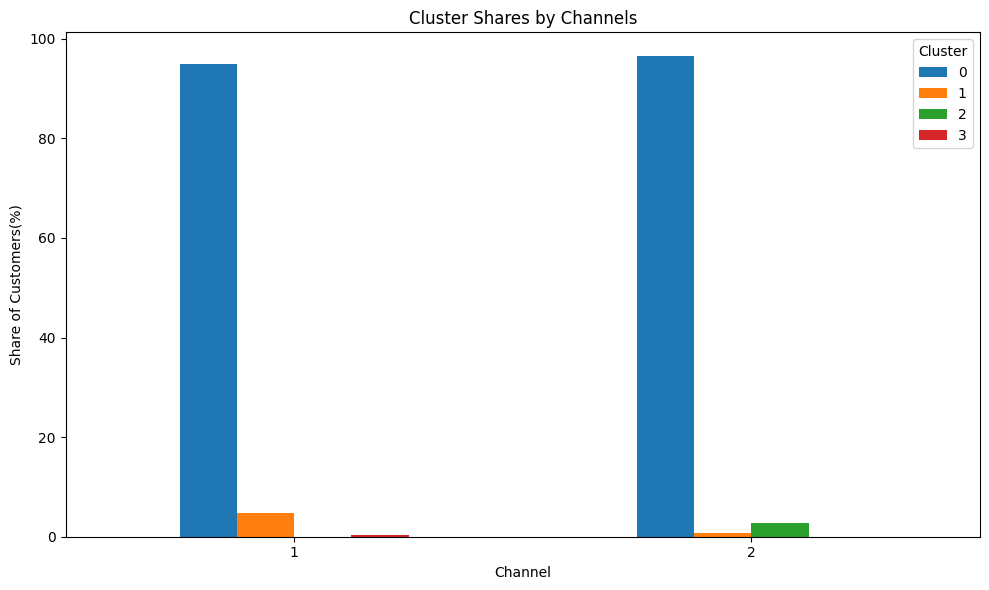

In [ ]:
channel_cluster_share = ( # the distribution of the clusters by channels for complete linkage
    pd.crosstab(df_final["channel"], df_final["comp_cluster"], normalize="index") * 100 # calculating the percentage of each cluster within each channel
)

# plotting the cluster shares by channel for complete linkage
ax = channel_cluster_share.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Channel")
plt.ylabel("Share of Customers(%)")
plt.title("Cluster Shares by Channels")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

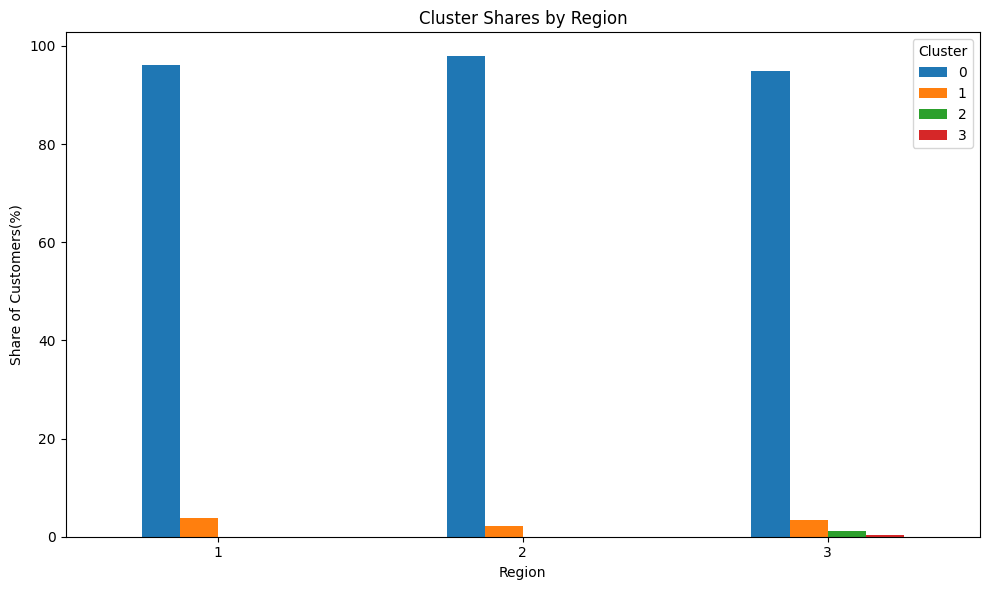

In [88]:
# plotting the cluster shares by region for complete linkage
region_cluster_share = (
    pd.crosstab(df_final["region"], df_final["comp_cluster"], normalize="index") * 100
)

ax = region_cluster_share.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Region")
plt.ylabel("Share of Customers(%)")
plt.title("Cluster Shares by Region")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

/var/folders/j9/ffq41s8s6gn1vs5k2pdq30pr0000gn/T/ipykernel_13294/3281303948.py:3: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.displot(df_final, x=col, hue="comp_cluster",


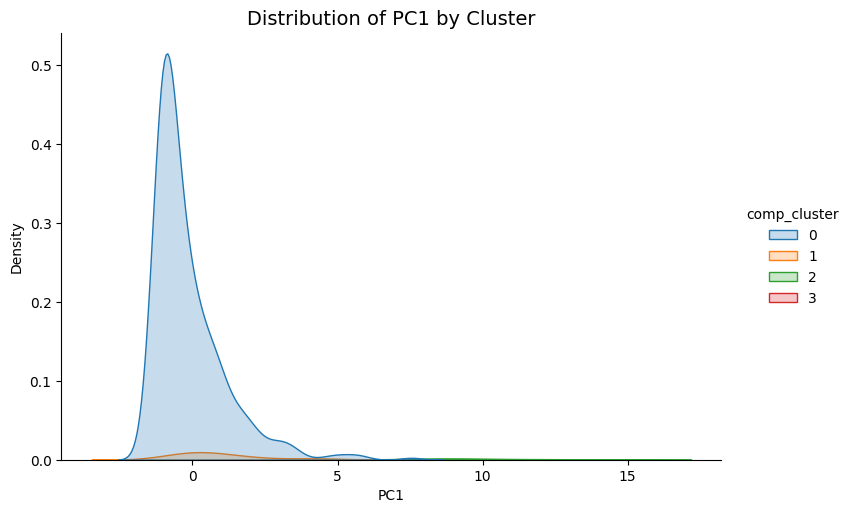

/var/folders/j9/ffq41s8s6gn1vs5k2pdq30pr0000gn/T/ipykernel_13294/3281303948.py:3: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.displot(df_final, x=col, hue="comp_cluster",


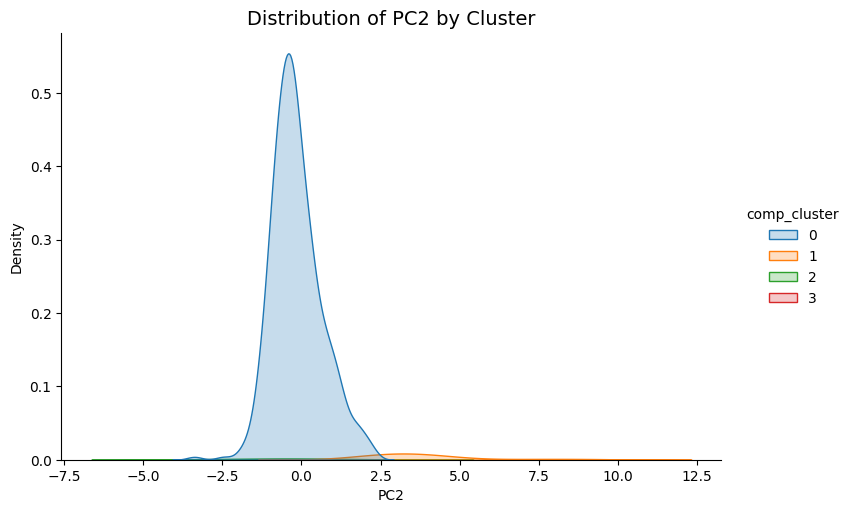

In [ ]:
# plotting the distribution of PC components by cluster for complete linkage
for col in ['PC1','PC2']:
    sns.displot(df_final, x=col, hue="comp_cluster",
                kind="kde", fill=True, height=5, aspect=1.5, palette="tab10")
    plt.title(f"Distribution of {col} by Cluster", fontsize=14)
    plt.show()

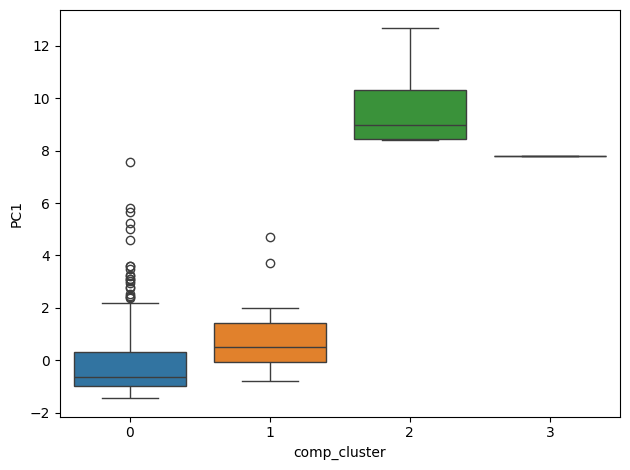

In [ ]:
# plotting boxplots of PC1 component by cluster for complete linkage
sns.boxplot(
    x=df_final["comp_cluster"],
    y=df_final["PC1"],
    hue=df_final["comp_cluster"],
    palette="tab10",
    legend=False
)
plt.tight_layout()


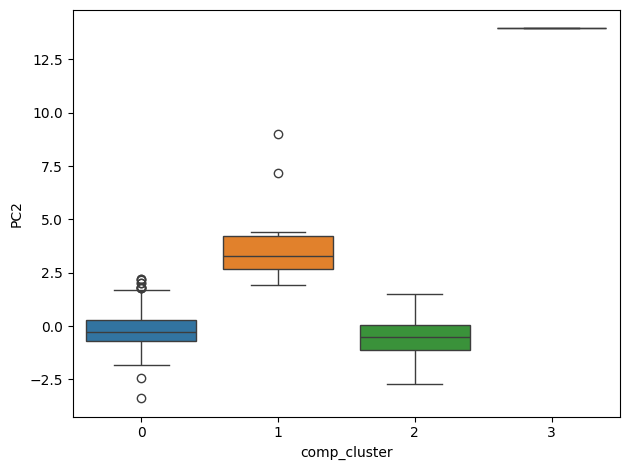

In [ ]:
sns.boxplot( 
    x=df_final["comp_cluster"],
    y=df_final["PC2"], # plotting boxplots of PC2 component by cluster for complete linkage
    hue=df_final["comp_cluster"],
    palette="tab10",
    legend=False
)
plt.tight_layout()

# LMM PCA & RESULTS

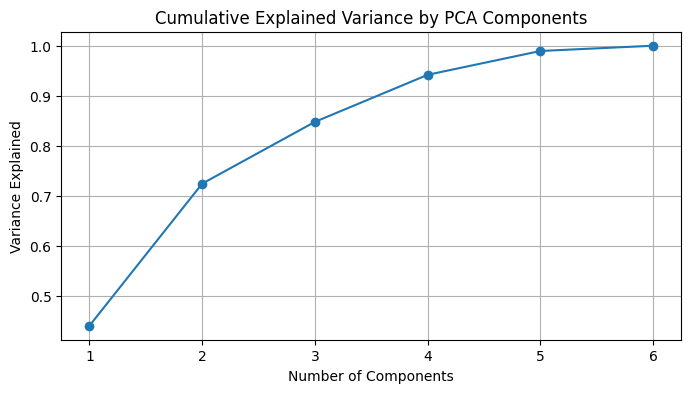

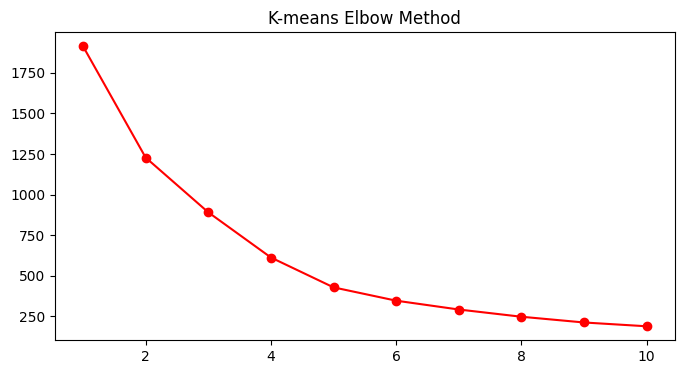

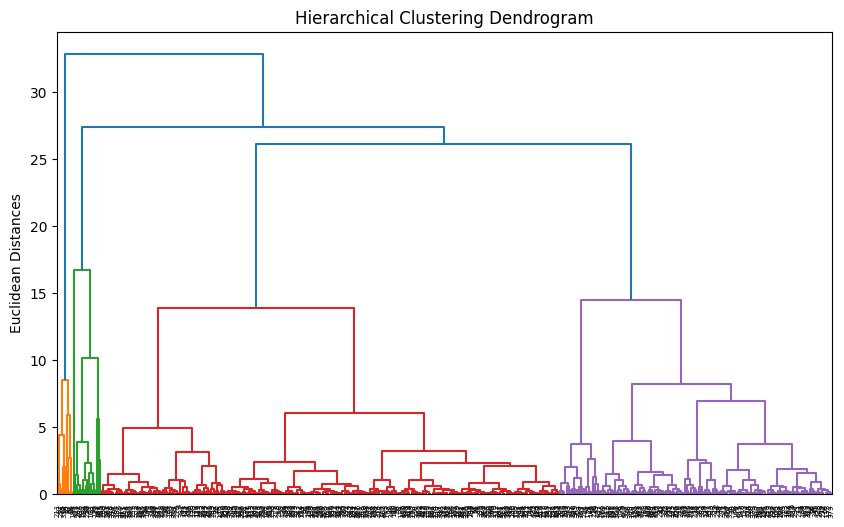

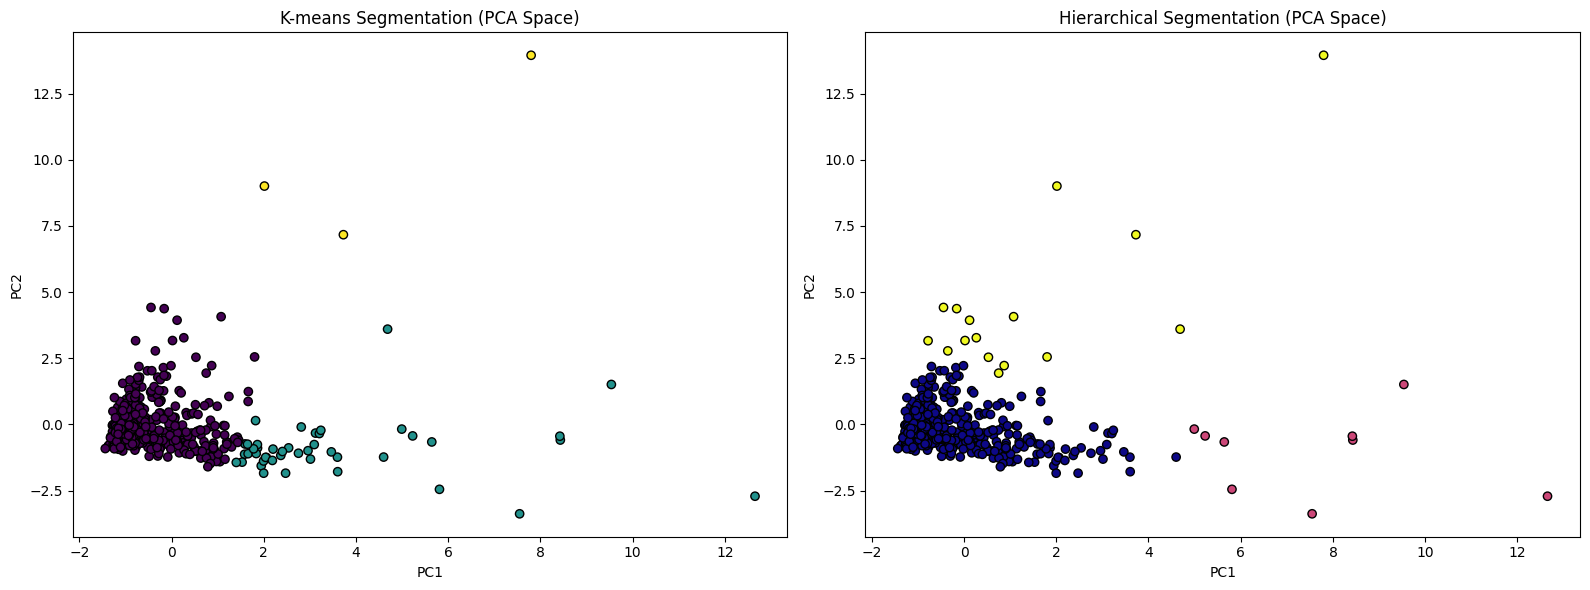

Pipeline Complete. Clustered data saved to 'Wholesale_Clustered_Results.csv'.


In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Load Dataset
df = pd.read_csv('/Users/sedakart/Desktop/SMM636-ML/Assignment 3/Wholesale customers data.csv')

# 2. Preprocessing
# We exclude 'Channel' and 'Region' for the PCA/Clustering as they are 
# identifiers rather than behavioral spending metrics.
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X = df[features]

# Standardizing is crucial for PCA and K-means as they are distance-based
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Principal Component Analysis (PCA)
# We initially keep all components to evaluate explained variance
pca_full = PCA()
pca_full.fit(X_scaled)

# Evaluate how many components to keep (Elbow in variance)
plt.figure(figsize=(8, 4))
plt.plot(range(1, 7), pca_full.explained_variance_ratio_.cumsum(), marker='o')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Variance Explained')
plt.grid(True)
plt.show()

# Transform data to 2 principal components for visualization and clustering
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 4. K-means Clustering
# Find optimal K using the Elbow Method
wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    km.fit(X_pca)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker='o', color='red')
plt.title('K-means Elbow Method')
plt.show()

# Final K-means model (e.g., k=3 based on elbow)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_pca)

# 5. Hierarchical Clustering
# Use a dendrogram to visualize potential clusters
plt.figure(figsize=(10, 6))
linkage_matrix = linkage(X_pca, method='ward')
dendrogram(linkage_matrix)
plt.title('Hierarchical Clustering Dendrogram')
plt.ylabel('Euclidean Distances')
plt.show()

# Apply Agglomerative Clustering
agg = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Hierarchical_Cluster'] = agg.fit_predict(X_pca)

# 6. Visualization of Results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# K-means Plot
ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=df['KMeans_Cluster'], cmap='viridis', edgecolors='k')
ax1.set_title('K-means Segmentation (PCA Space)')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')

# Hierarchical Plot
ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=df['Hierarchical_Cluster'], cmap='plasma', edgecolors='k')
ax2.set_title('Hierarchical Segmentation (PCA Space)')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')

plt.tight_layout()
plt.show()

# Export clustered data
df.to_csv('Wholesale_Clustered_Results.csv', index=False)
print("Pipeline Complete. Clustered data saved to 'Wholesale_Clustered_Results.csv'.")